# Guerra, armas e relações internacionais

Gasto militar, transferências de armas e conflitos armados, de 2014 ao dado mais recente (2025).

Este notebook roda do início ao fim: baixa o que faltar, limpa, e mostra cada figura com a tabela que a sustenta. As figuras são gravadas em `outputs/figures/`. As fontes, versões e ressalvas estão em `data/README.md`.

**Três avisos antes de ler os gráficos**

1. **TIV não é dinheiro.** As transferências de armas do SIPRI são medidas em *trend-indicator value*, um indicador de volume de capacidade militar. Não é preço nem receita.
2. **O UCDP conta só conflitos com um governo entre as partes** e ao menos 25 mortes em batalha no ano. Violência entre grupos não estatais e ataques a civis ficam de fora.
3. **Nenhum número foi completado.** Onde a fonte não tem dado, há lacuna.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import pandas as pd
from IPython.display import Image, display
from src import config as c, download, limpeza, graficos as g

pd.options.display.float_format = lambda v: f"{v:,.1f}".replace(",", "X").replace(".", ",").replace("X", ".")

def mostrar(n):
    """Gera a figura n nos dois formatos e exibe a versão 16:9."""
    for fmt in g.FORMATOS:
        g.FIGURAS[n](fmt)
    arq = sorted(c.FIGURAS.glob(f"fig{n:02d}_*.png"))
    display(Image(filename=str([a for a in arq if "instagram" not in a.name][0]), width=980))

## 0. Dados

`download.main()` só baixa o que ainda não está em `data/raw/`. A agregação do Sinesp (Brasil) é lenta na primeira vez, cerca de 2 minutos por ano, e fica em cache depois.

In [2]:
fontes = download.main()
limpeza.main()
manifesto = json.loads(c.MANIFESTO.read_text(encoding="utf-8"))
pd.DataFrame(manifesto).T[["data_acesso", "versao"]]

[aviso] nomes sem ISO3 (ficam fora dos cruzamentos por país): ['Czechoslovakia', 'European Union', 'German Democratic Republic', 'Government of Hyderabad', 'Government of South Vietnam', 'Government of South Yemen', 'Northern Cyprus', 'Western Sahara', 'Yemen, North']
[ok] tabelas em data/processed: ['armas_tiv.csv', 'brasil_sinesp_eventos.csv', 'conflitos_por_pais.csv', 'conflitos_por_tipo.csv', 'gasto_banco_mundial.csv', 'gasto_sipri_paises.csv', 'gasto_sipri_regioes.csv', 'mortes_por_conflito.csv', 'mortes_por_regiao.csv']


,data_acesso,versao
banco_mundial_MS.MIL.XPND.CD,2026-10-13,"WDI, atualização 2026-10-08"
banco_mundial_MS.MIL.XPND.GD.ZS,2026-10-13,"WDI, atualização 2026-10-08"
banco_mundial_paises,2026-10-13,metadados de países
sipri_milex,2026-10-13,SIPRI Military Expenditure Database 1949-2025 ...
ucdp_acd,2026-10-13,UCDP versão 26.1
ucdp_brd,2026-10-13,UCDP versão 26.1
sipri_tiv_exportadores,2026-10-13,"SIPRI Arms Transfers Database, 1992-2025. Data..."
sipri_tiv_importadores,2026-10-13,"SIPRI Arms Transfers Database, 1992-2025. Data..."
sinesp_2015,2026-10-13,Sinesp VDE 2015 (arquivo de s/d)
sinesp_2016,2026-10-13,Sinesp VDE 2016 (arquivo de s/d)


## 1. Quanto o mundo gasta

Série do SIPRI em dólares constantes de 2024 (1988–2025) e, abaixo, o gasto como parcela do PIB mundial desde 1960 (Banco Mundial). Os dois painéis contam histórias diferentes: o valor absoluto é recorde, o esforço relativo à economia não é.

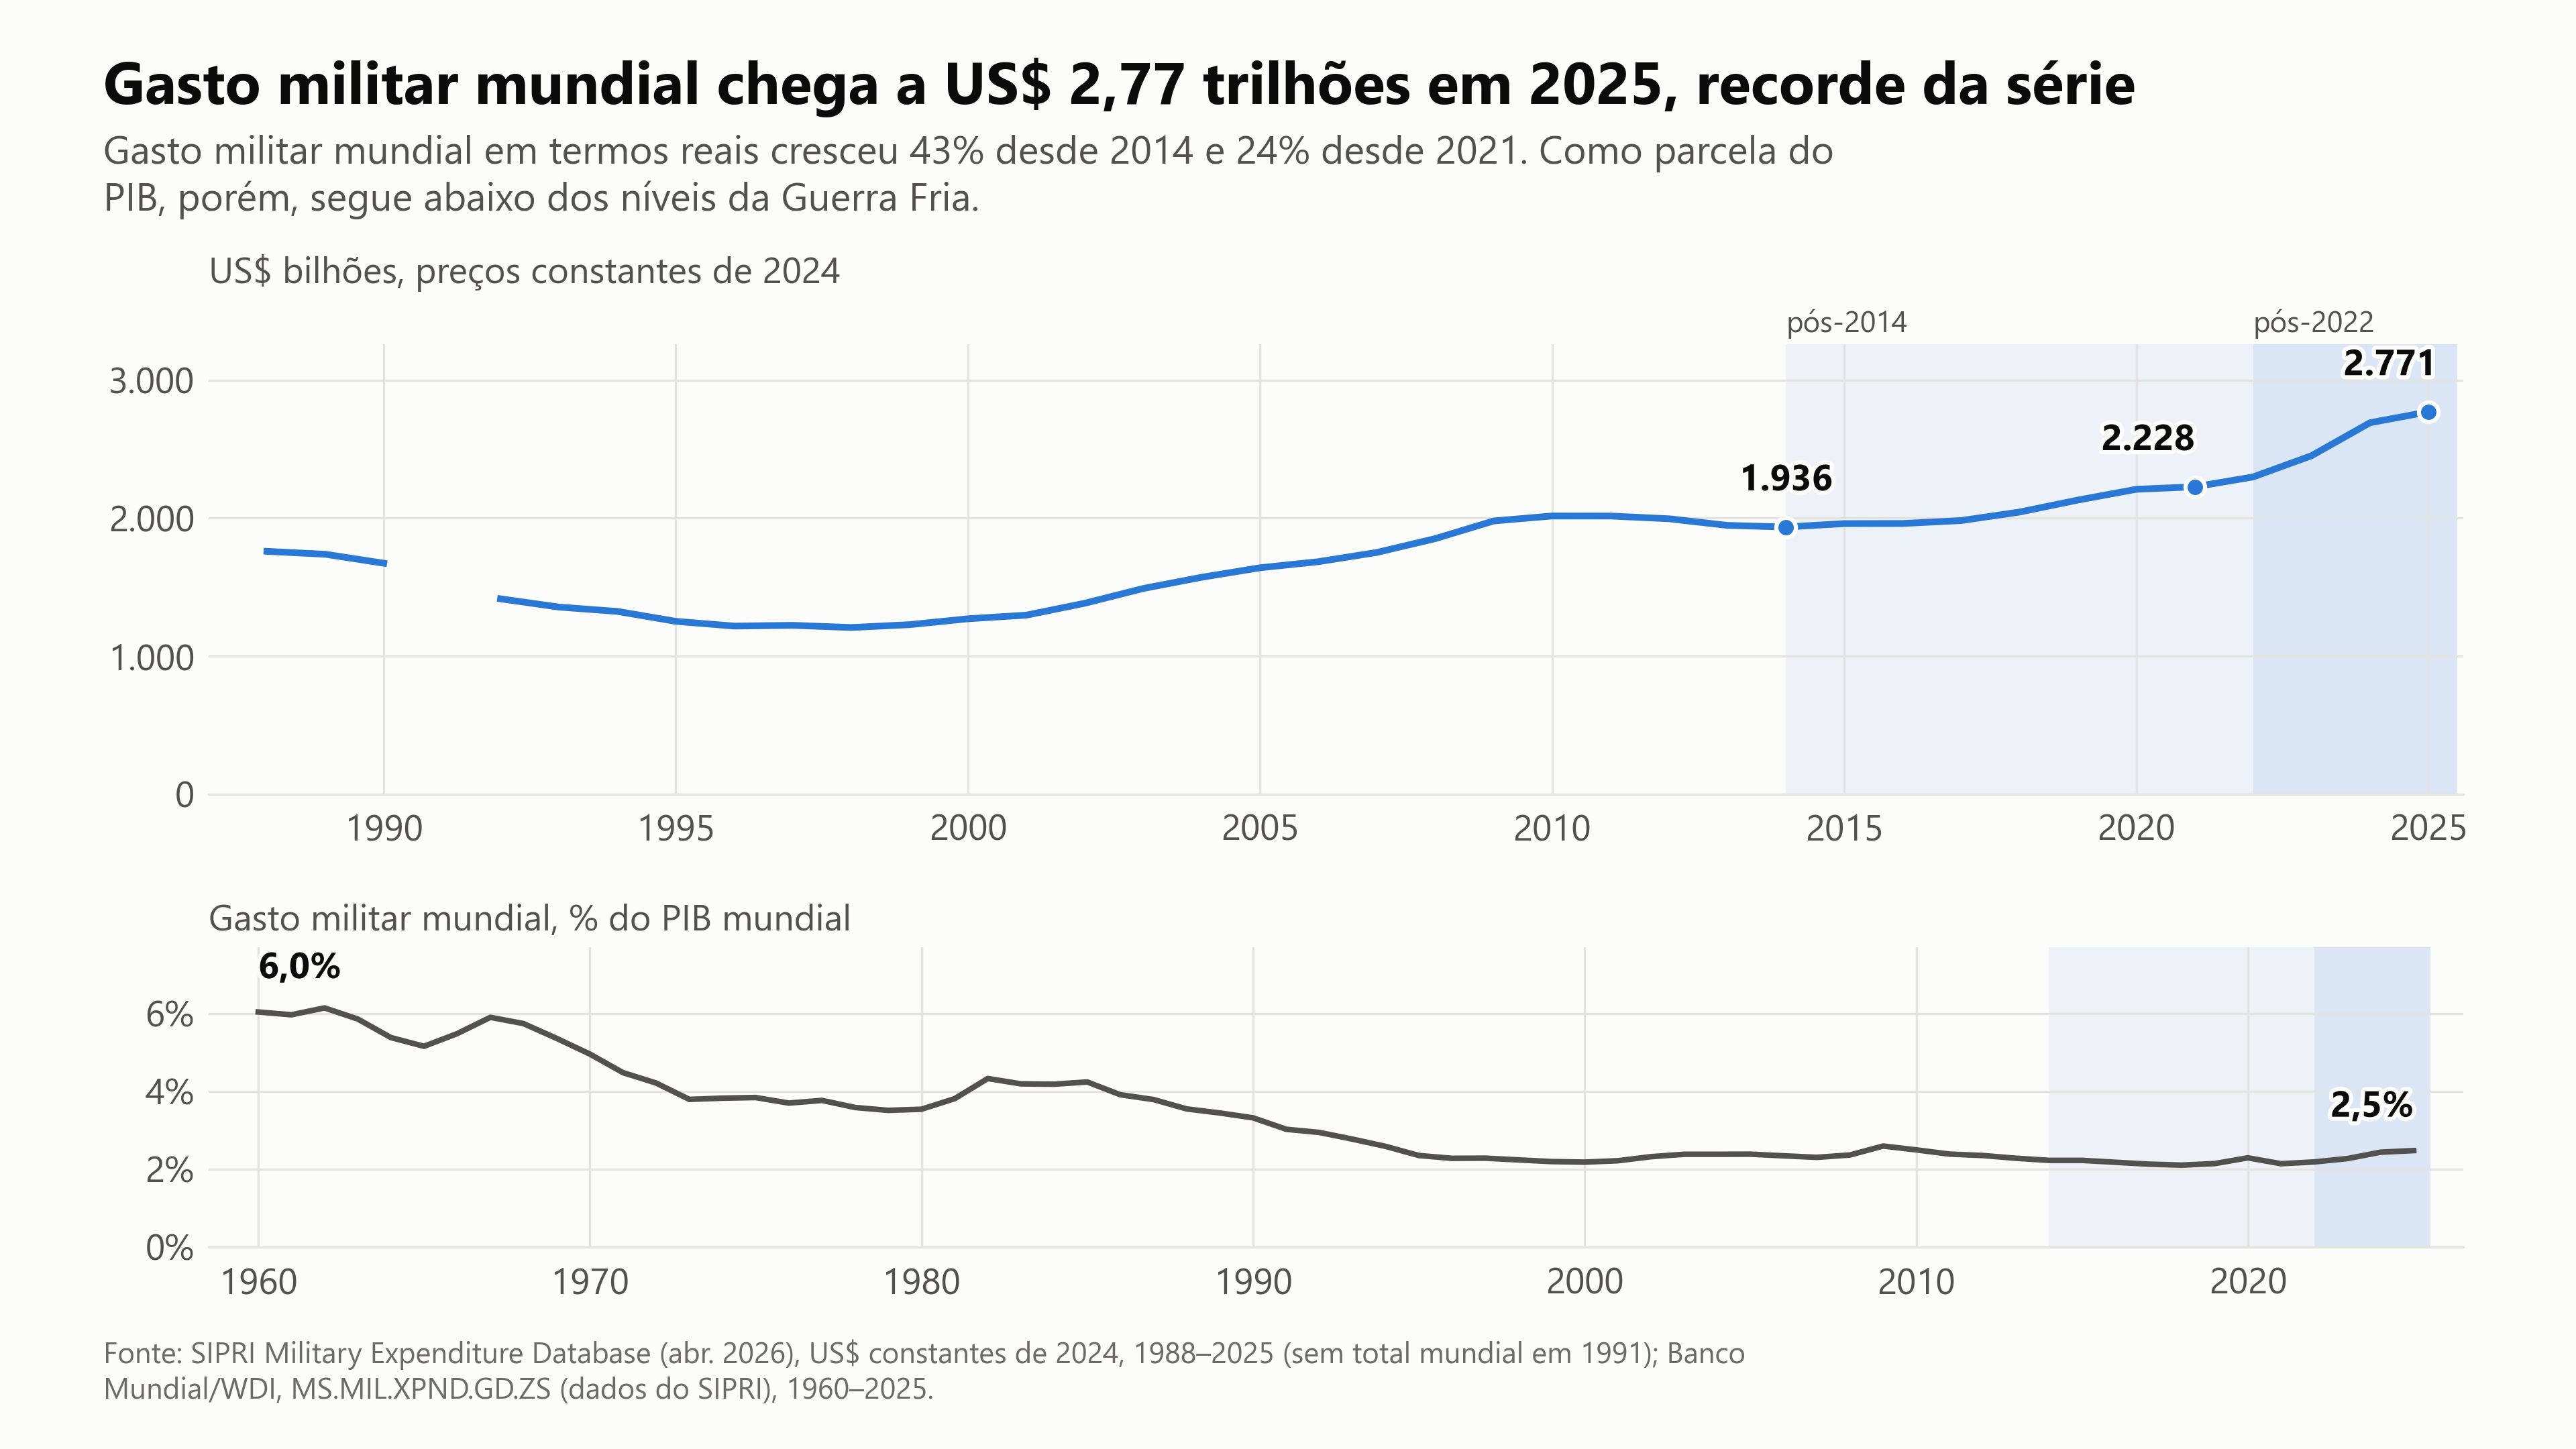

,US$ bi (2024),% do PIB
ano,,
1988,"1.759,9","3,5"
2000,"1.270,8","2,2"
2014,"1.936,2","2,2"
2021,"2.227,8","2,1"
2022,"2.299,3","2,2"
2023,"2.453,4","2,3"
2024,"2.692,3","2,4"
2025,"2.771,3","2,5"


In [3]:
mostrar(1)
reg = pd.read_csv(c.PROCESSED / "gasto_sipri_regioes.csv")
mundo = reg[reg.regiao == "World"].set_index("ano").usd_bi_const2024
wb = pd.read_csv(c.PROCESSED / "gasto_banco_mundial.csv")
pib = wb[wb.iso3 == "WLD"].set_index("ano").gasto_pct_pib
pd.DataFrame({"US$ bi (2024)": mundo, "% do PIB": pib}).loc[[1988, 2000, 2014, 2021, 2022, 2023, 2024, 2025]]

## 2. A Europa e a régua da OTAN

A meta de 2% do PIB vem da Cúpula de Gales (2014). Em Haia (junho de 2025) os aliados a substituíram por 5% até 2035: 3,5% em defesa propriamente dita e 1,5% em gastos correlatos. O dado abaixo segue a definição do SIPRI, que não é idêntica à da OTAN. O Brasil entra como contraste.

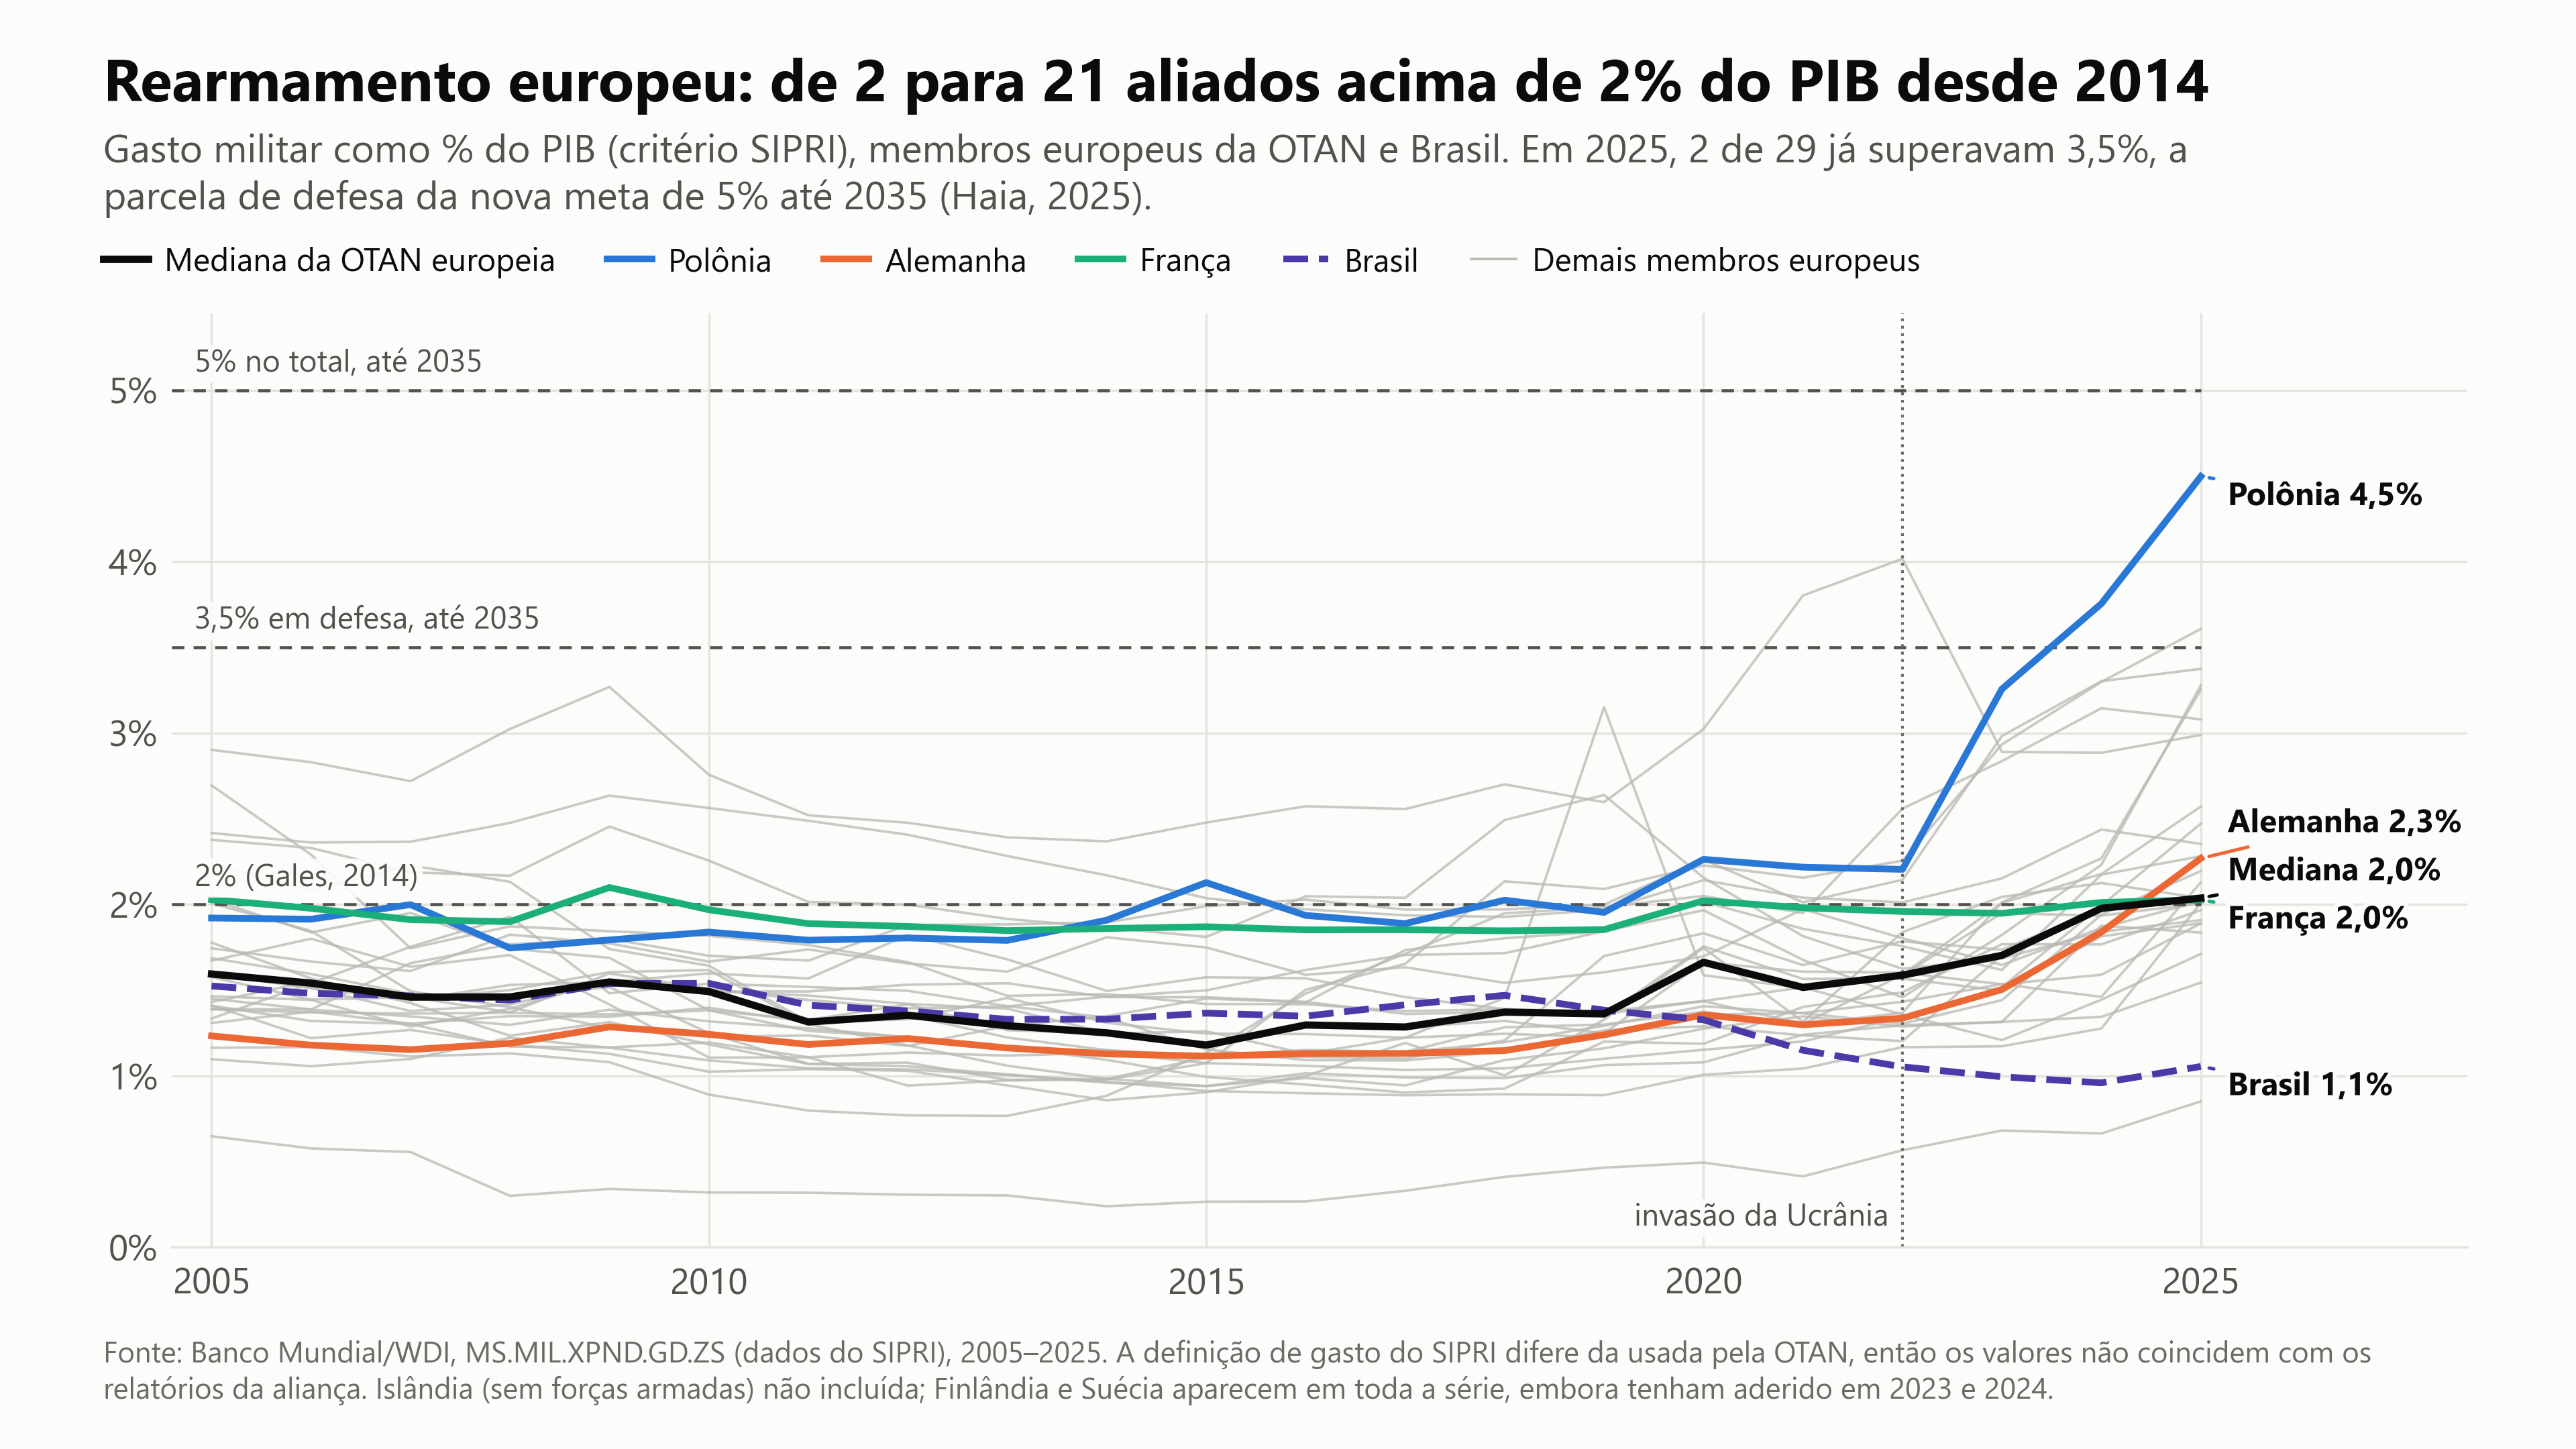

,mediana (% PIB),países ≥ 2%,"países ≥ 3,5%",Brasil (% PIB)
ano,,,,
2014,"1,3",2,0,"1,3"
2015,"1,2",3,0,"1,4"
2016,"1,3",3,0,"1,3"
2017,"1,3",2,0,"1,4"
2018,"1,4",4,0,"1,5"
2019,"1,4",4,0,"1,4"
2020,"1,7",9,0,"1,3"
2021,"1,5",5,1,"1,1"
2022,"1,6",6,1,"1,1"


In [4]:
mostrar(2)
o = wb[wb.iso3.isin(c.OTAN_EUROPA)].pivot(index="ano", columns="iso3", values="gasto_pct_pib")
pd.DataFrame({"mediana (% PIB)": o.median(axis=1), "países ≥ 2%": (o >= 2).sum(axis=1),
              "países ≥ 3,5%": (o >= 3.5).sum(axis=1), "Brasil (% PIB)": wb[wb.iso3 == "BRA"].set_index("ano").gasto_pct_pib}).loc[2014:]

## 3. Quem mais gasta

Valores em dólares constantes de 2024, o que permite ler a variação de dez anos em termos reais. A barra da Ucrânia no painel da direita está cortada e marcada: sem isso, as demais ficariam ilegíveis.

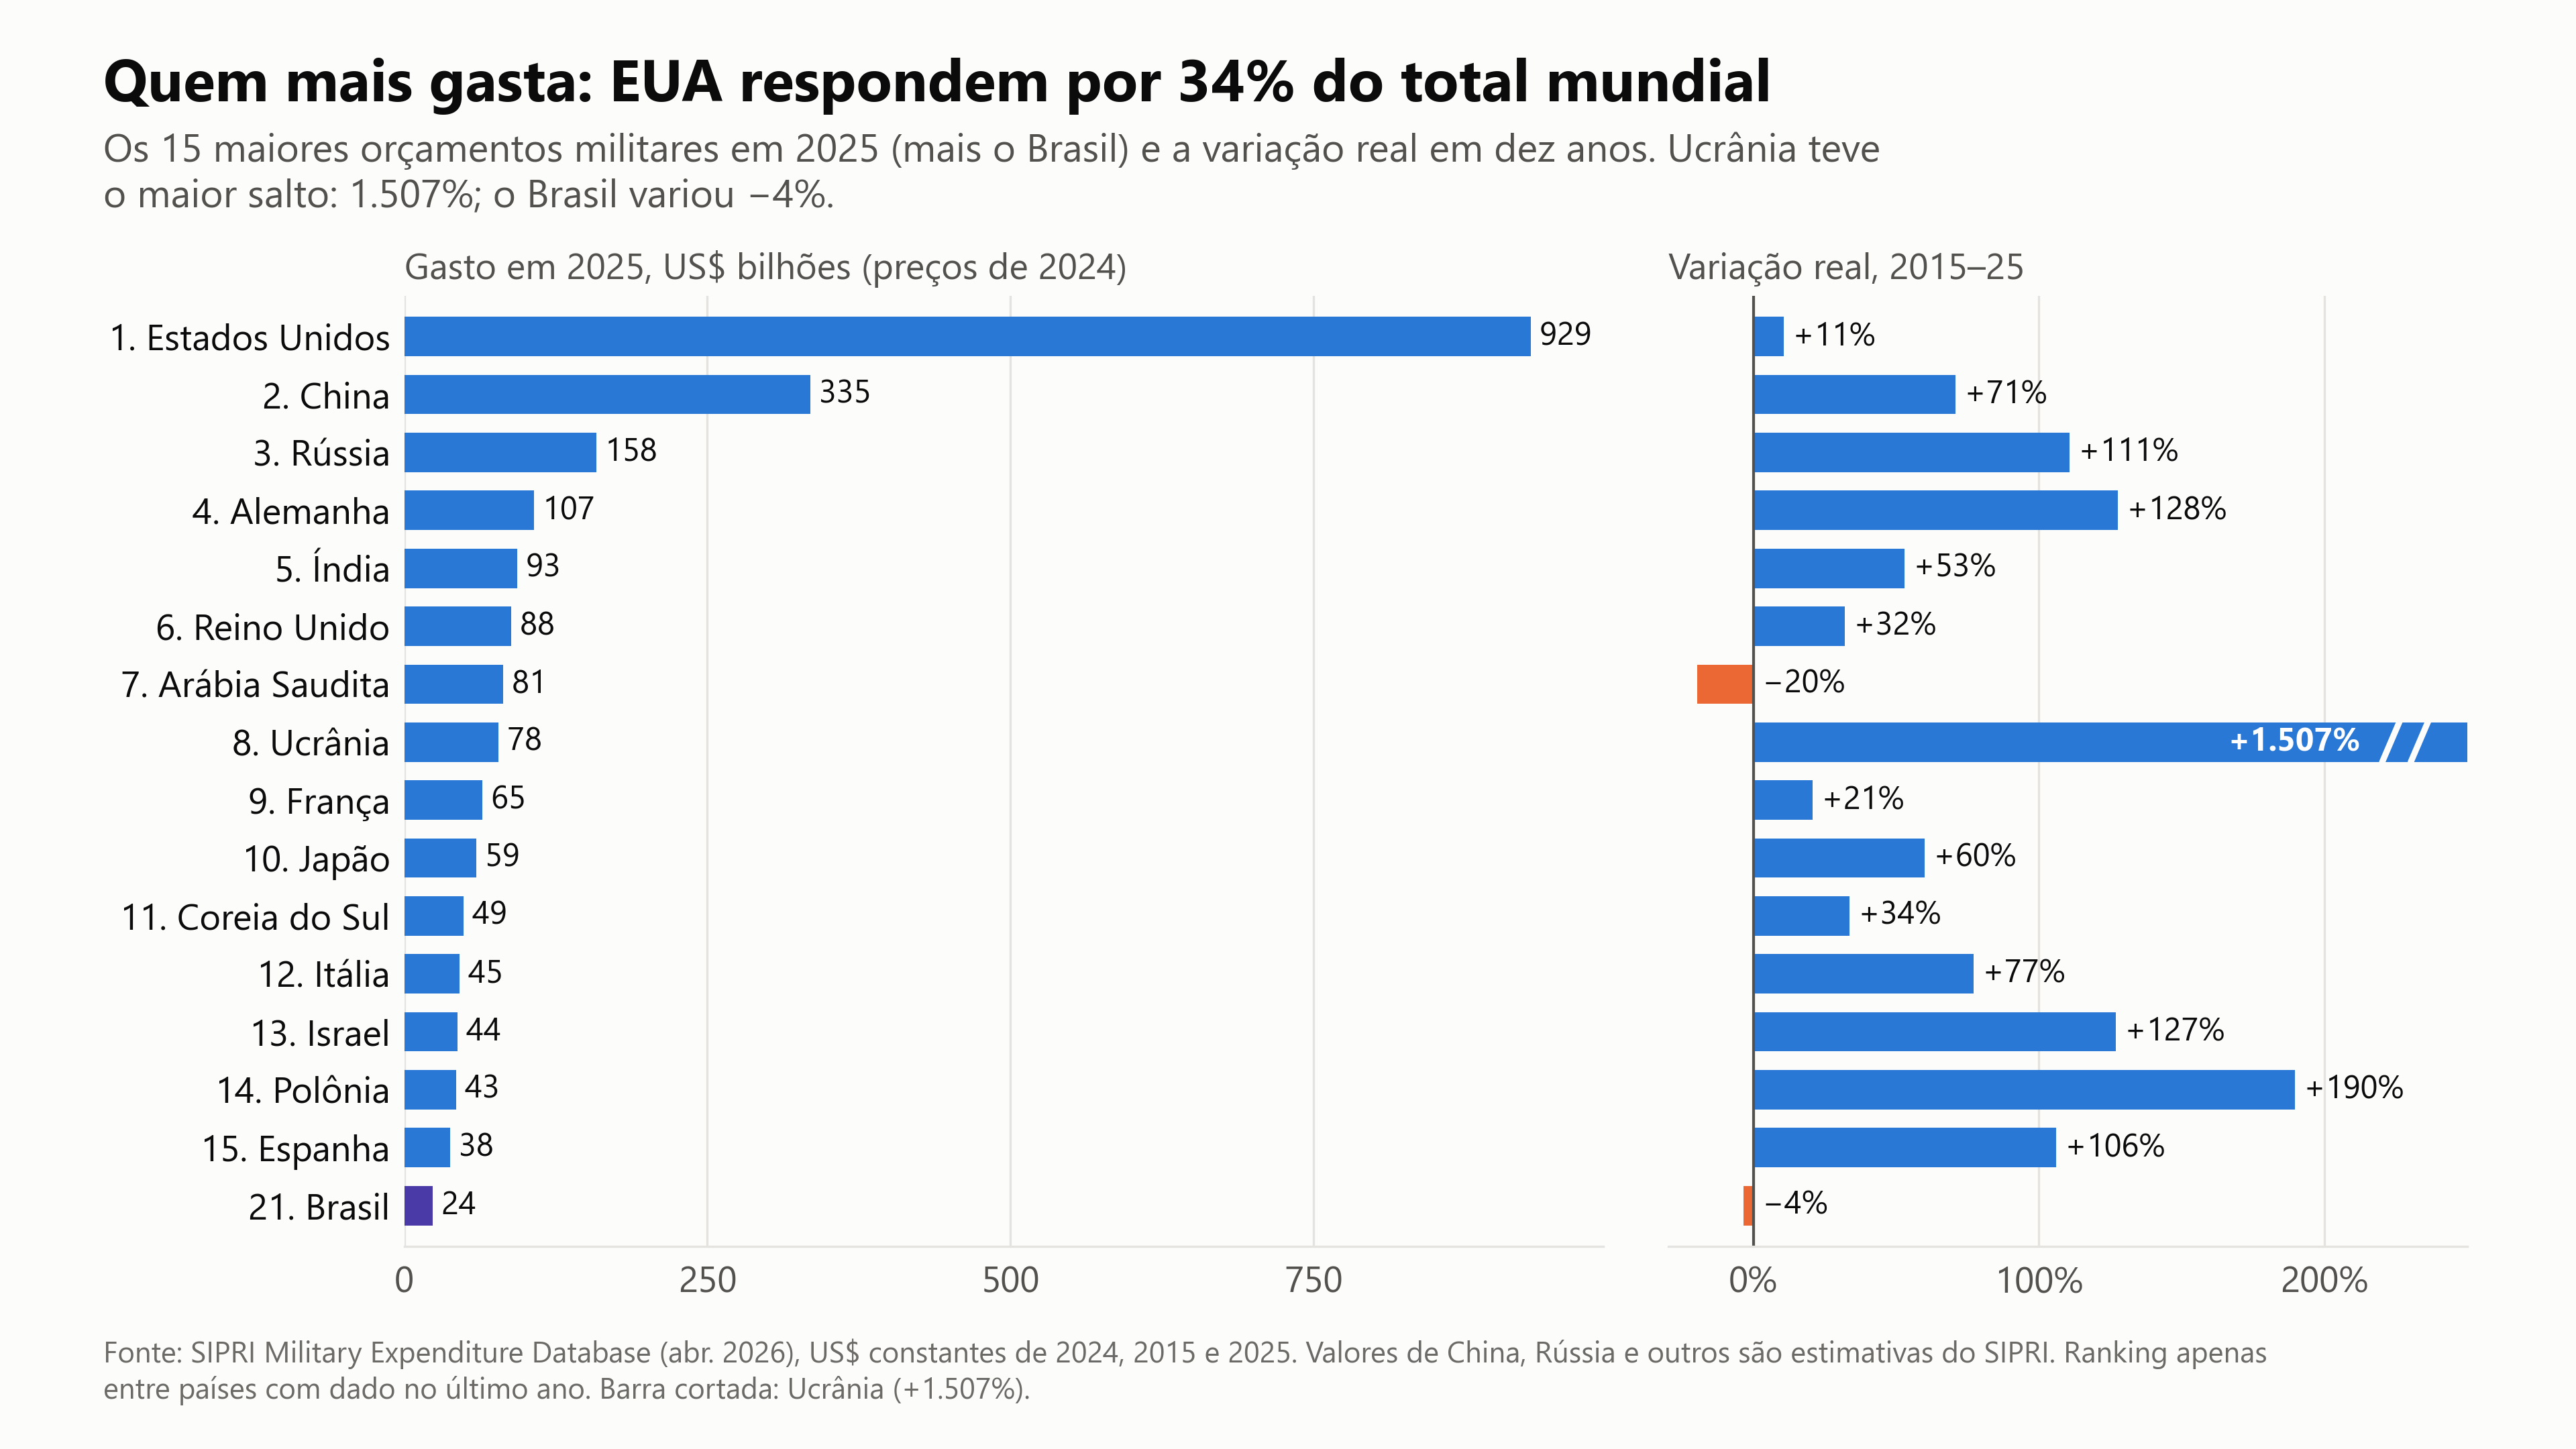

In [5]:
mostrar(3)

## 4. Quem vende e quem compra armas

Somas de cinco anos em **TIV (não é valor monetário)**. Janelas de cinco anos são o padrão do SIPRI porque as entregas se concentram em poucos anos.

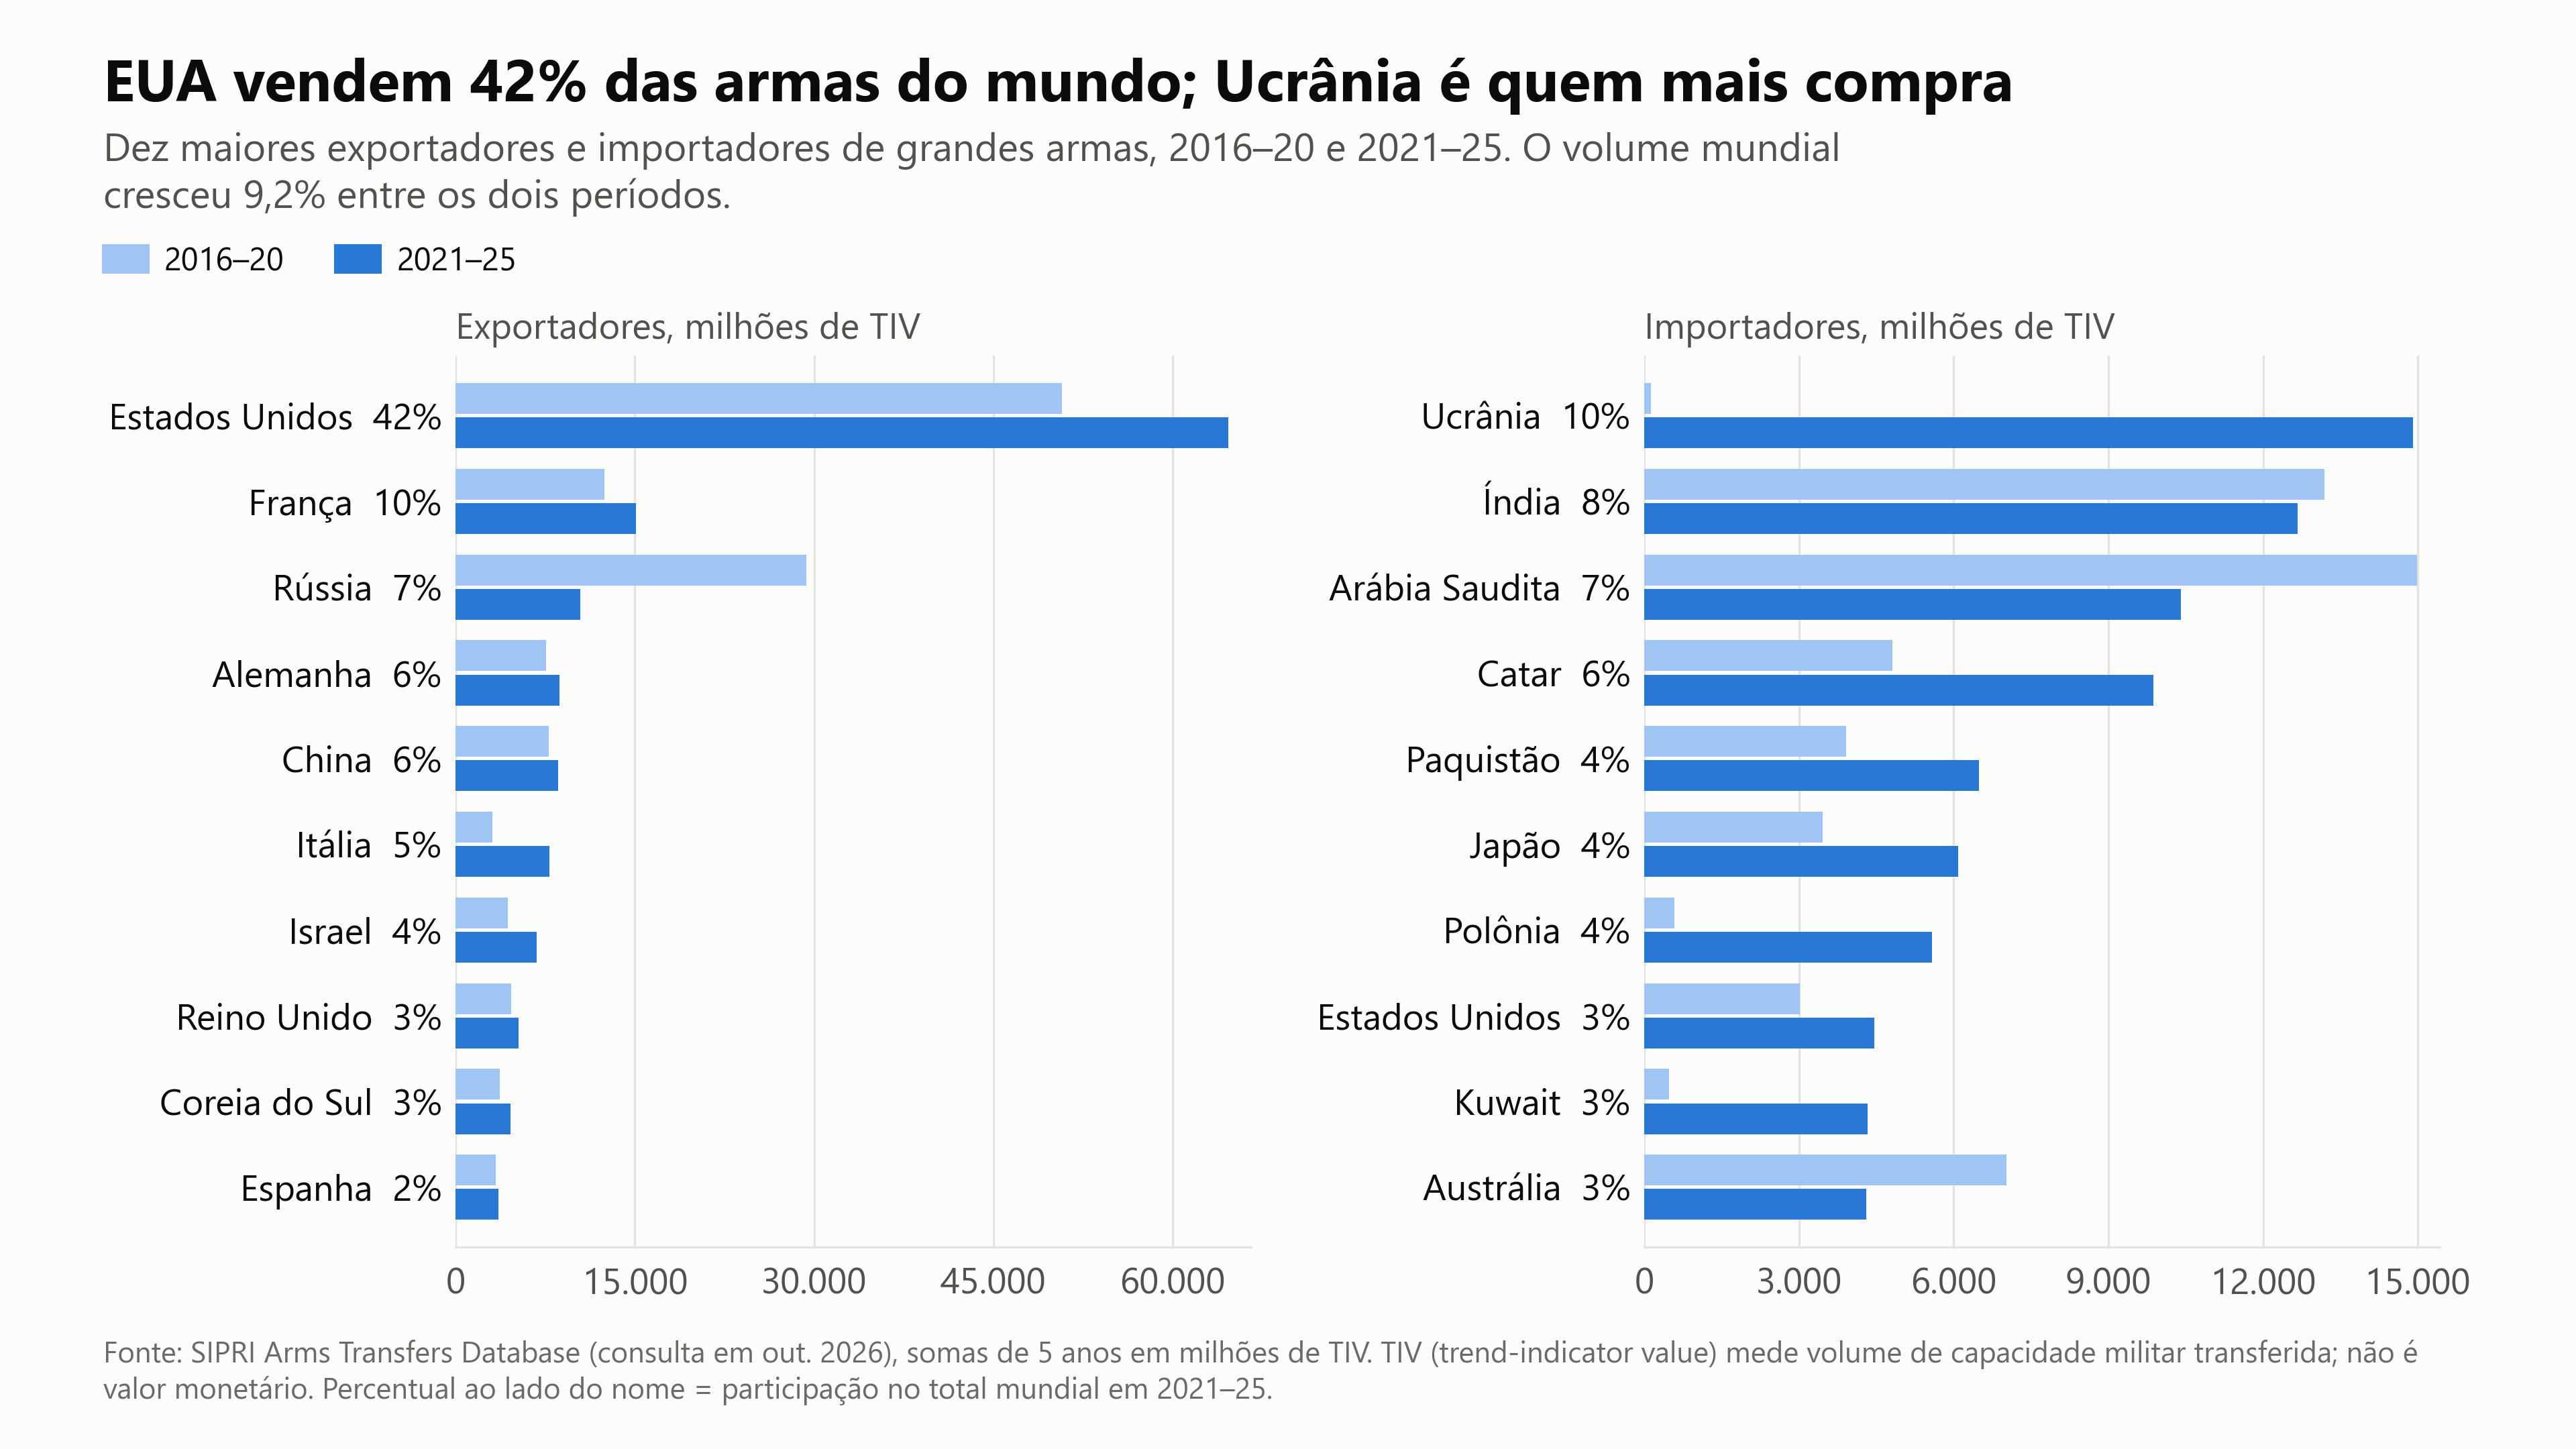

,pais,TIV 2016–20,TIV 2021–25,% do mundo
109,United States,"50.763,0","64.657,0","41,9"
37,France,"12.439,0","15.074,0","9,8"
86,Russia,"29.325,0","10.411,0","6,8"
39,Germany,"7.567,0","8.711,0","5,7"
20,China,"7.760,0","8.584,0","5,6"
50,Italy,"3.047,0","7.838,0","5,1"
49,Israel,"4.356,0","6.779,0","4,4"
108,United Kingdom,"4.668,0","5.285,0","3,4"
94,South Korea,"3.693,0","4.564,0","3,0"
95,Spain,"3.329,0","3.549,0","2,3"


In [6]:
if (c.PROCESSED / "armas_tiv.csv").exists():
    mostrar(4)
    exp, t1, t2 = g._janelas_tiv("exportador")
    display(exp.head(10).assign(participacao=lambda d: d.p2 / t2 * 100)[["pais", "p1", "p2", "participacao"]]
            .rename(columns={"p1": "TIV 2016–20", "p2": "TIV 2021–25", "participacao": "% do mundo"}))
else:
    print("Sem TIV em data/raw: ver data/README.md para o download manual.")

## 5. Quantas guerras

Conflitos de base estatal ativos por ano, segundo o UCDP/PRIO. "Intraestatal internacionalizado" é a guerra civil em que ao menos um lado recebe tropas de outro Estado.

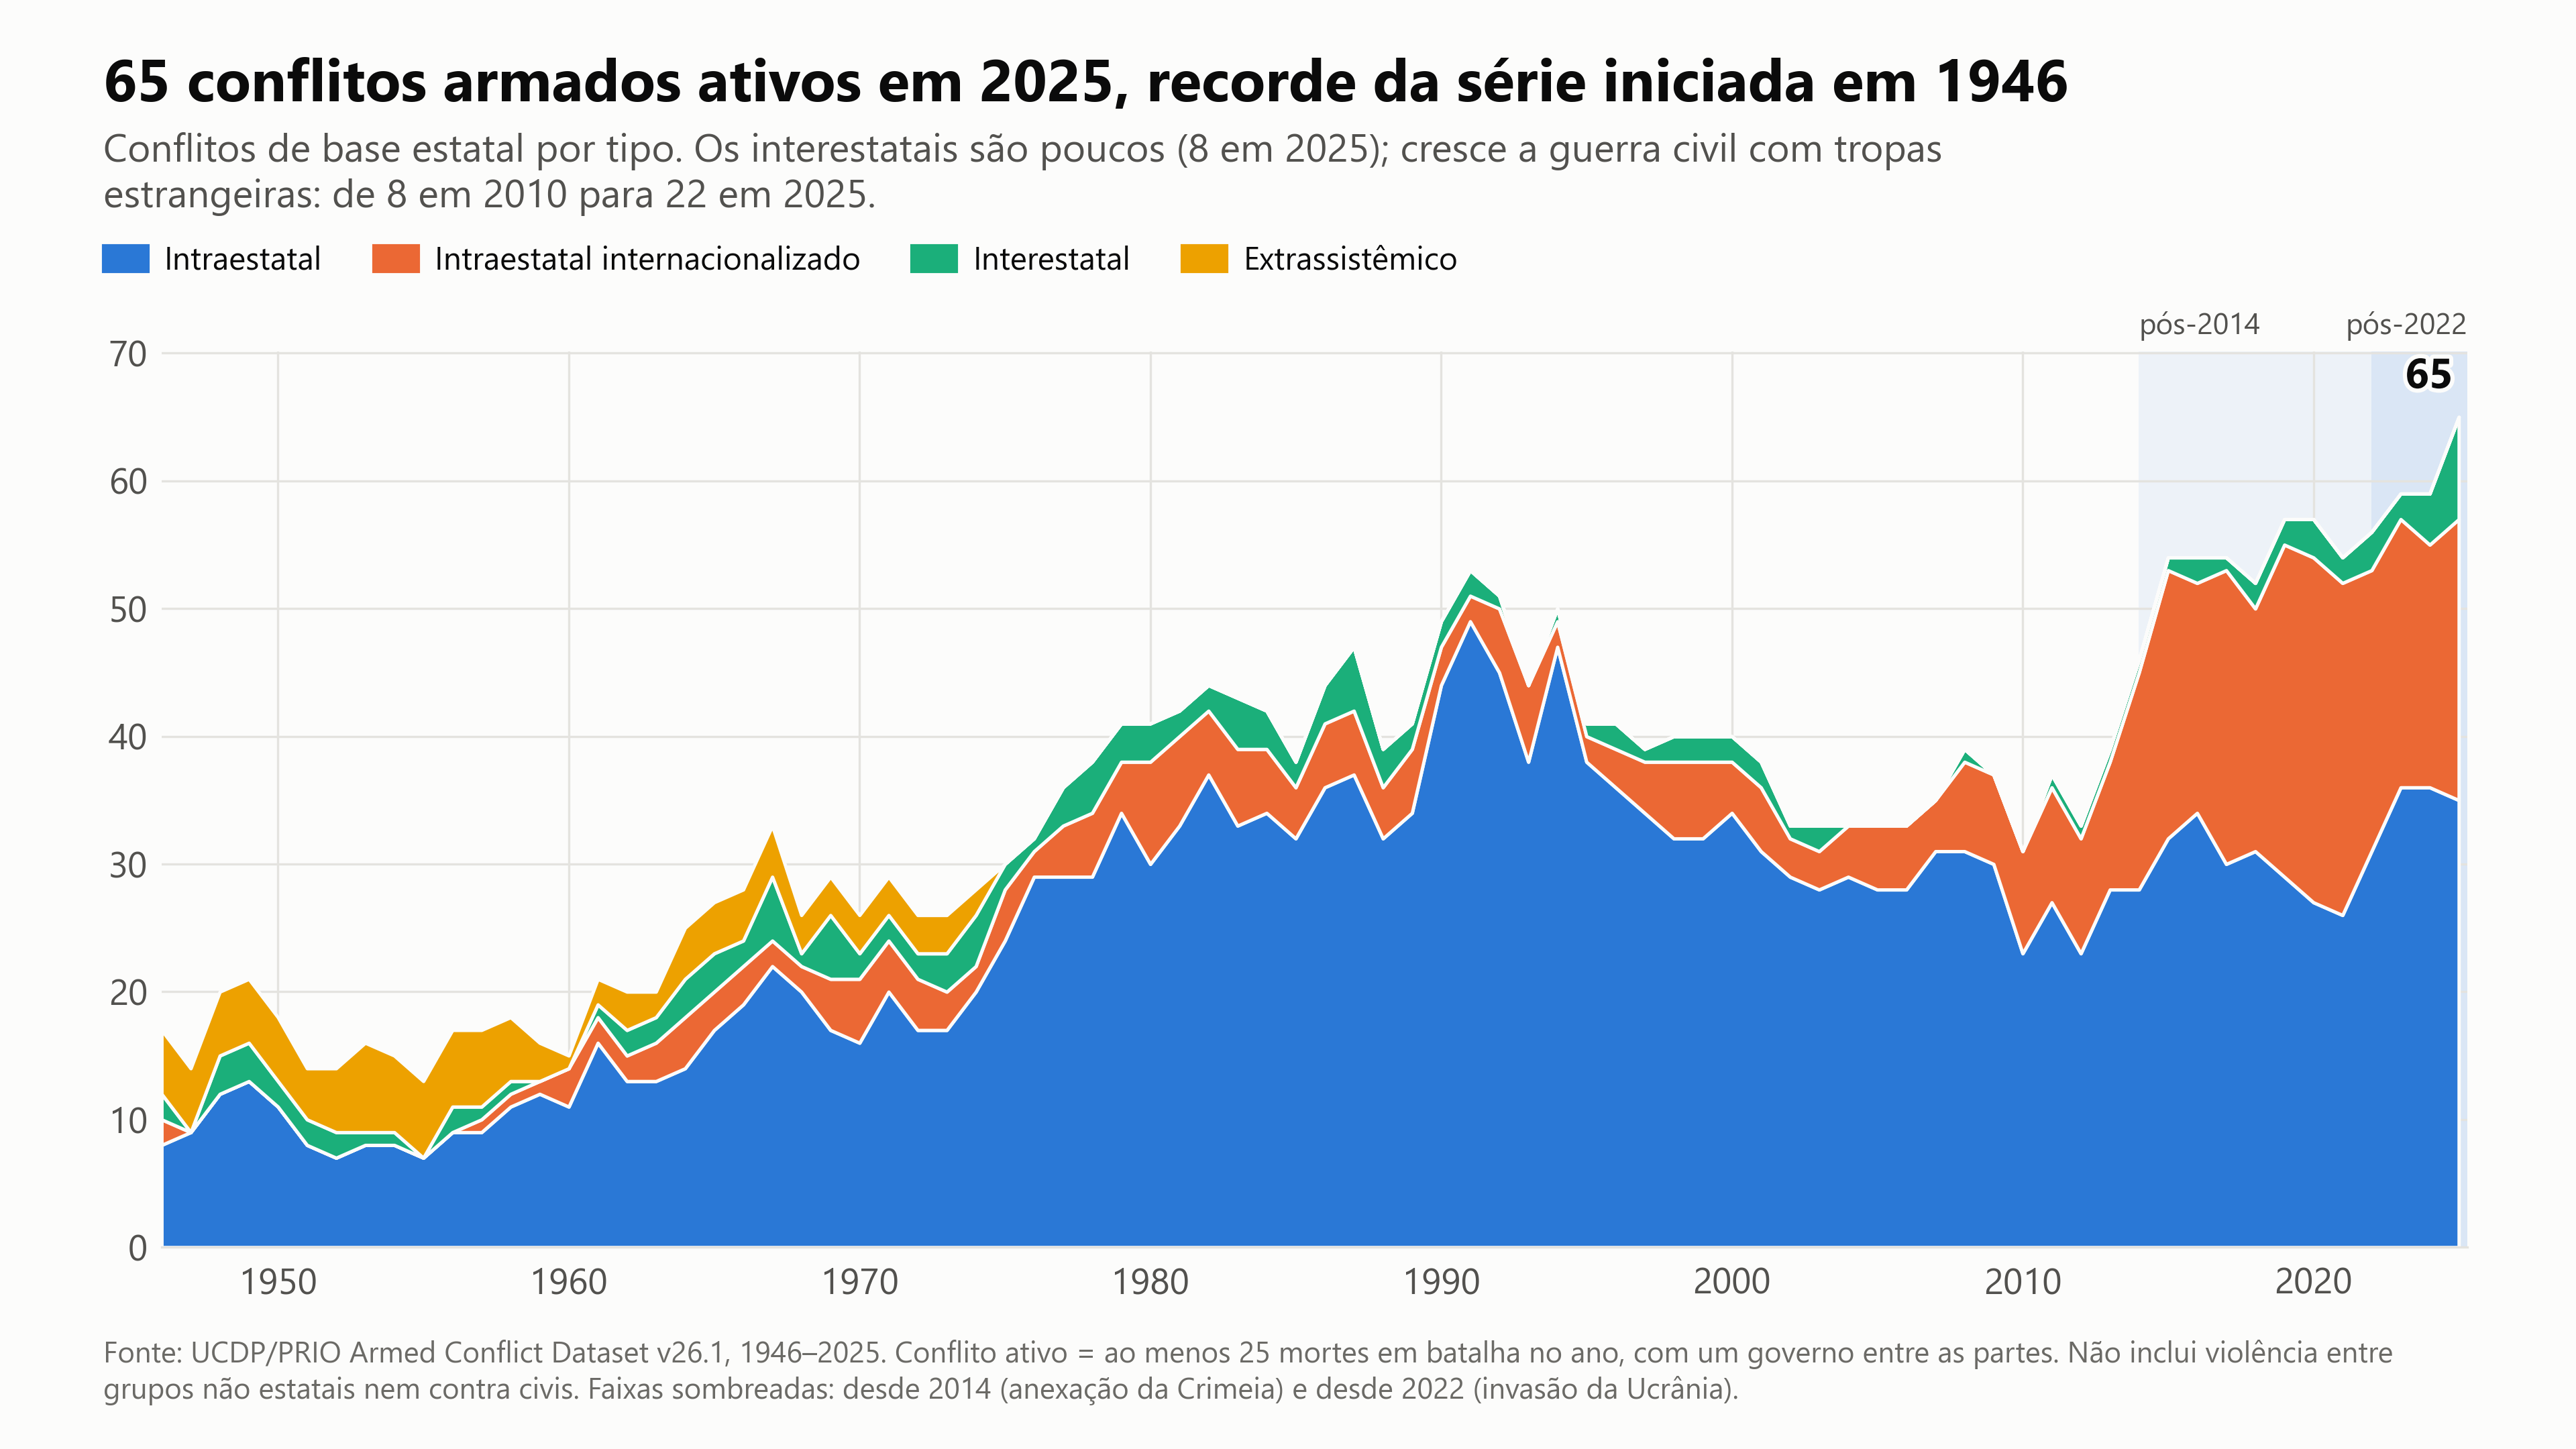

tipo,Extrassistêmico,Interestatal,Intraestatal,Intraestatal internacionalizado,total
ano,,,,,
1991,0,2,49,2,53
2010,0,0,23,8,31
2014,0,1,28,17,46
2021,0,2,26,26,54
2022,0,3,31,22,56
2023,0,2,36,21,59
2024,0,4,36,19,59
2025,0,8,35,22,65


In [7]:
mostrar(5)
ct = pd.read_csv(c.PROCESSED / "conflitos_por_tipo.csv").pivot(index="ano", columns="tipo", values="n_conflitos").fillna(0).astype(int)
ct.assign(total=ct.sum(axis=1)).loc[[1991, 2010, 2014, 2021, 2022, 2023, 2024, 2025]]

## 6. Quantas mortes

Mortes em batalha por região. O traço fino sobre cada barra mostra o intervalo entre a estimativa baixa e a alta do UCDP; ele é largo, e isso é parte do resultado.

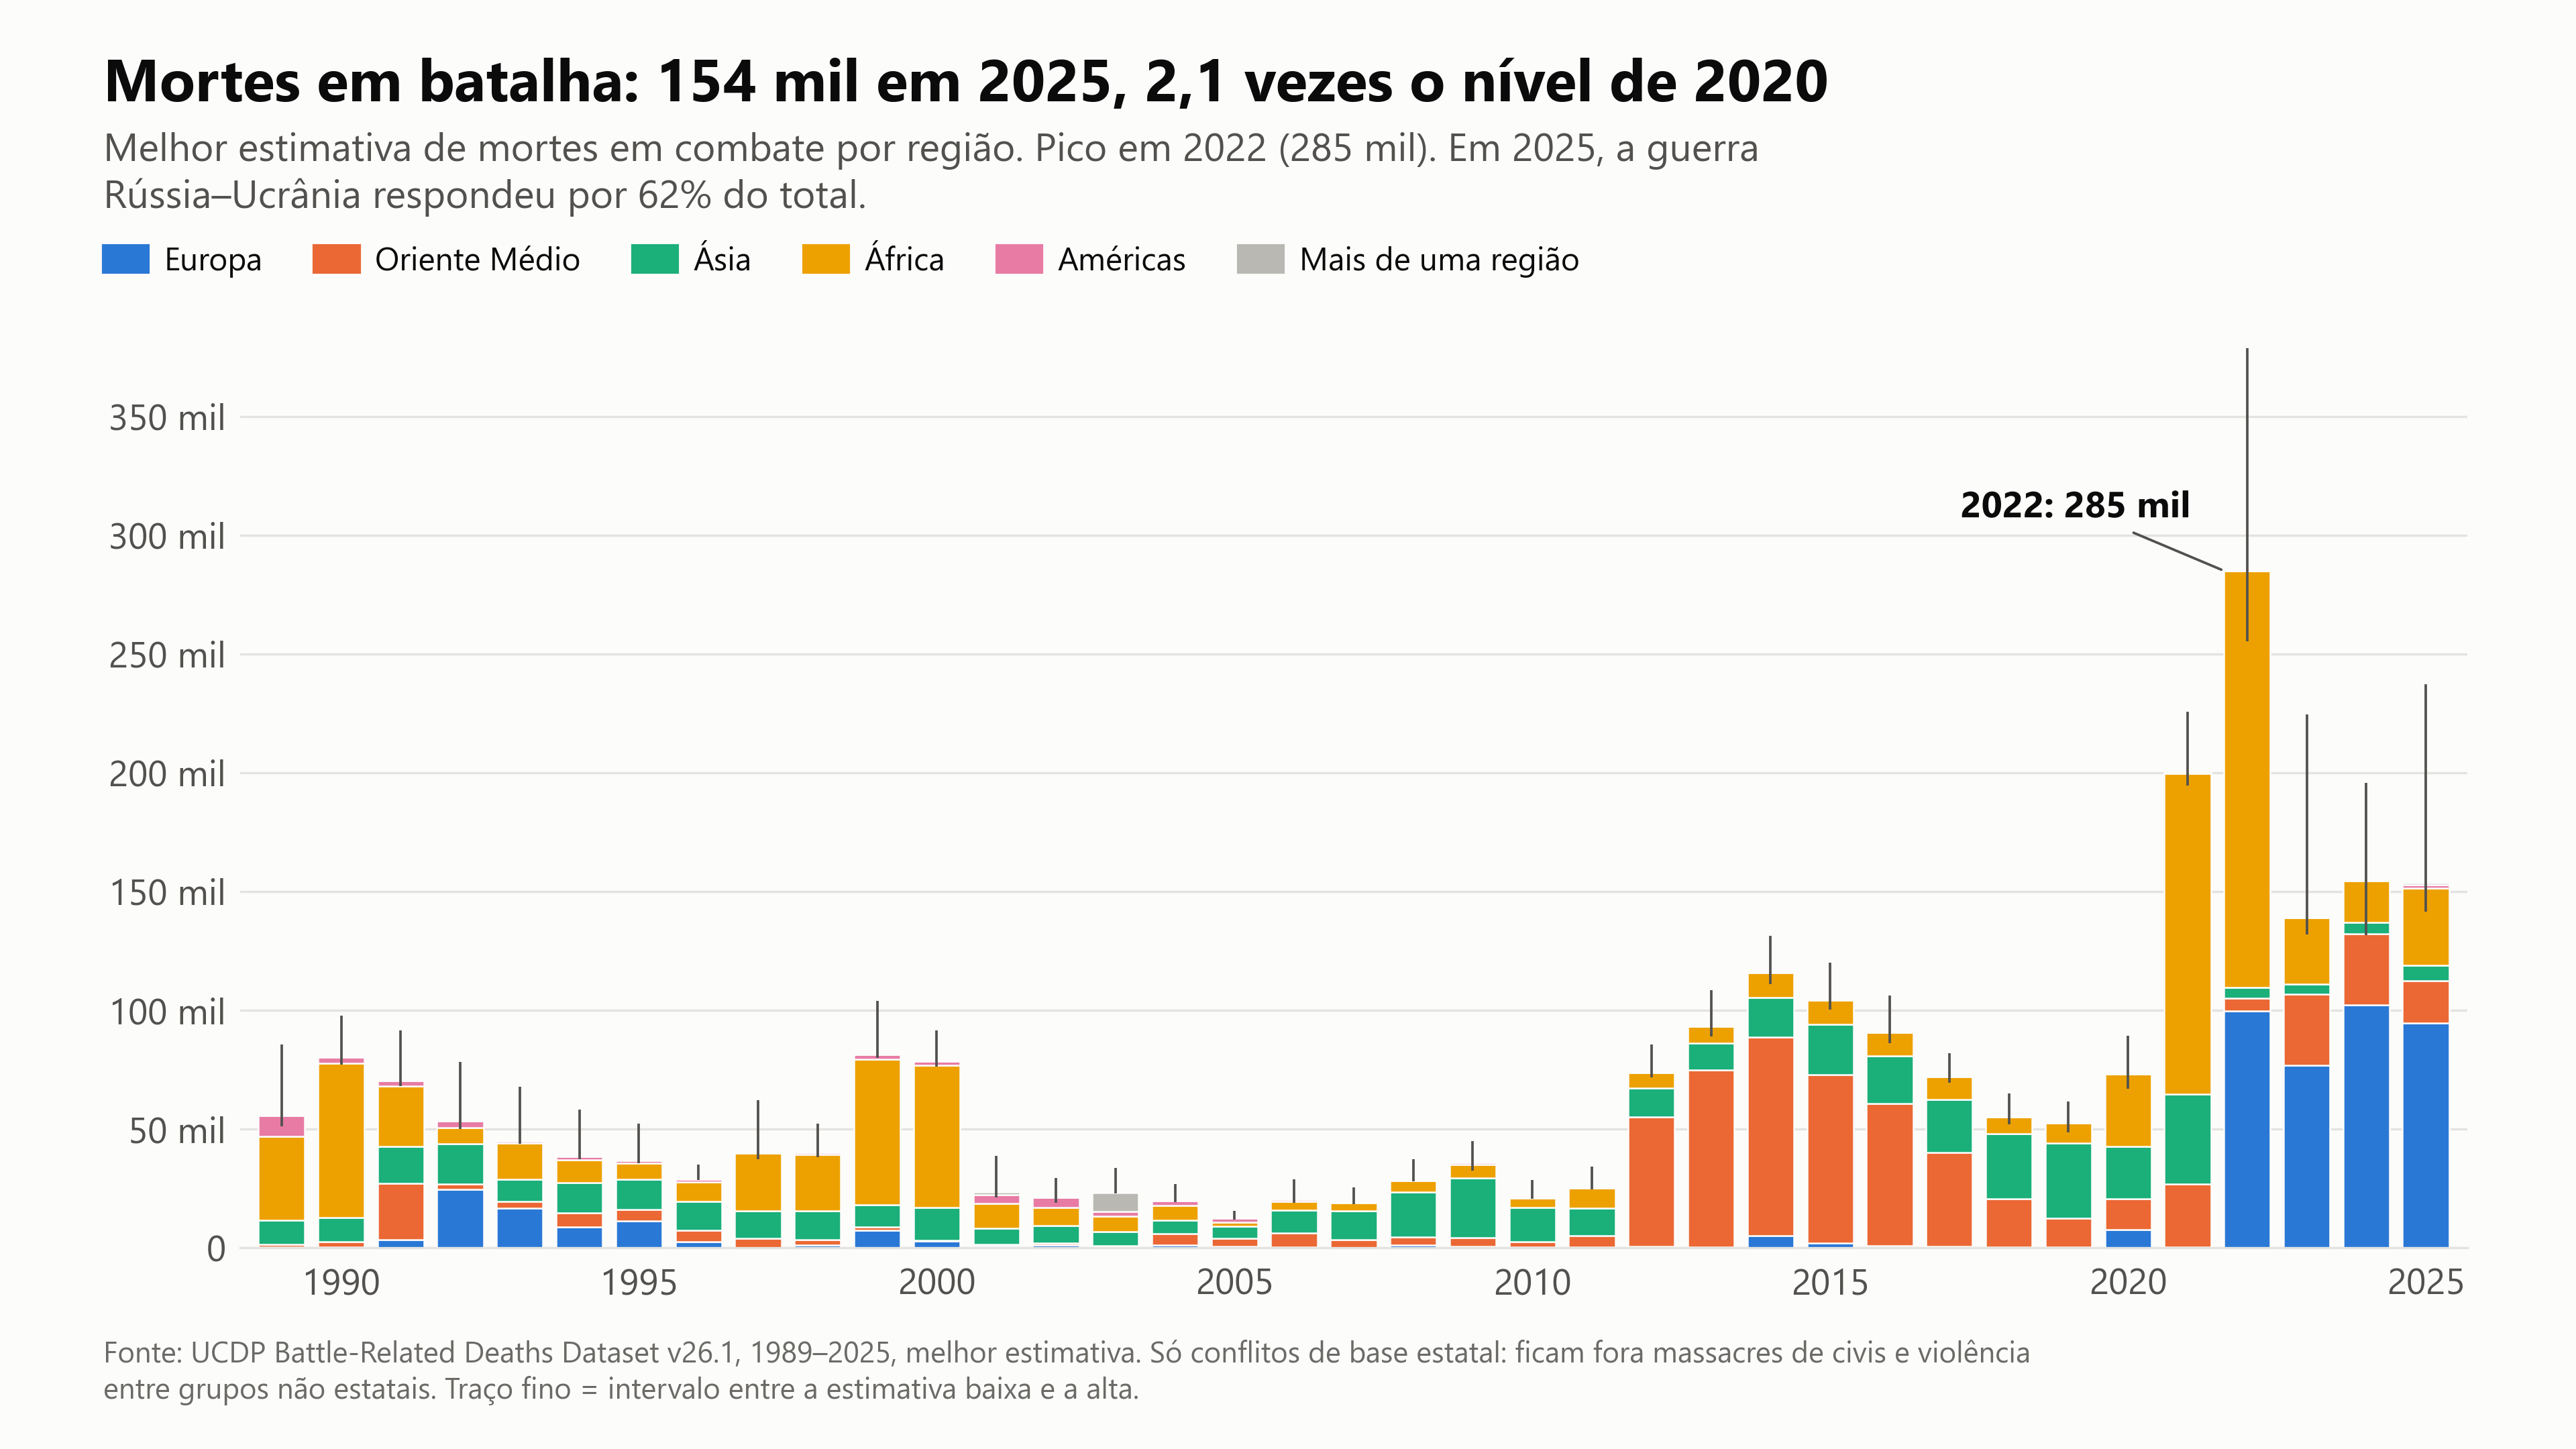

,"mortes em batalha, 2025"
local,
"Russia (Soviet Union), Ukraine",94741
Israel,14771
Sudan,12269
DR Congo (Zaire),4464
Ethiopia,4312
Somalia,3095
Pakistan,3091
Burkina Faso,3031
Myanmar (Burma),2083


In [8]:
mostrar(6)
mc = pd.read_csv(c.PROCESSED / "mortes_por_conflito.csv")
mc[mc.ano == mc.ano.max()].groupby("local").mortes.sum().nlargest(10).to_frame("mortes em batalha, 2025")

## 7. Concentração do mercado de armas

Participação nas exportações mundiais em janelas móveis de cinco anos (**TIV, não monetário**).

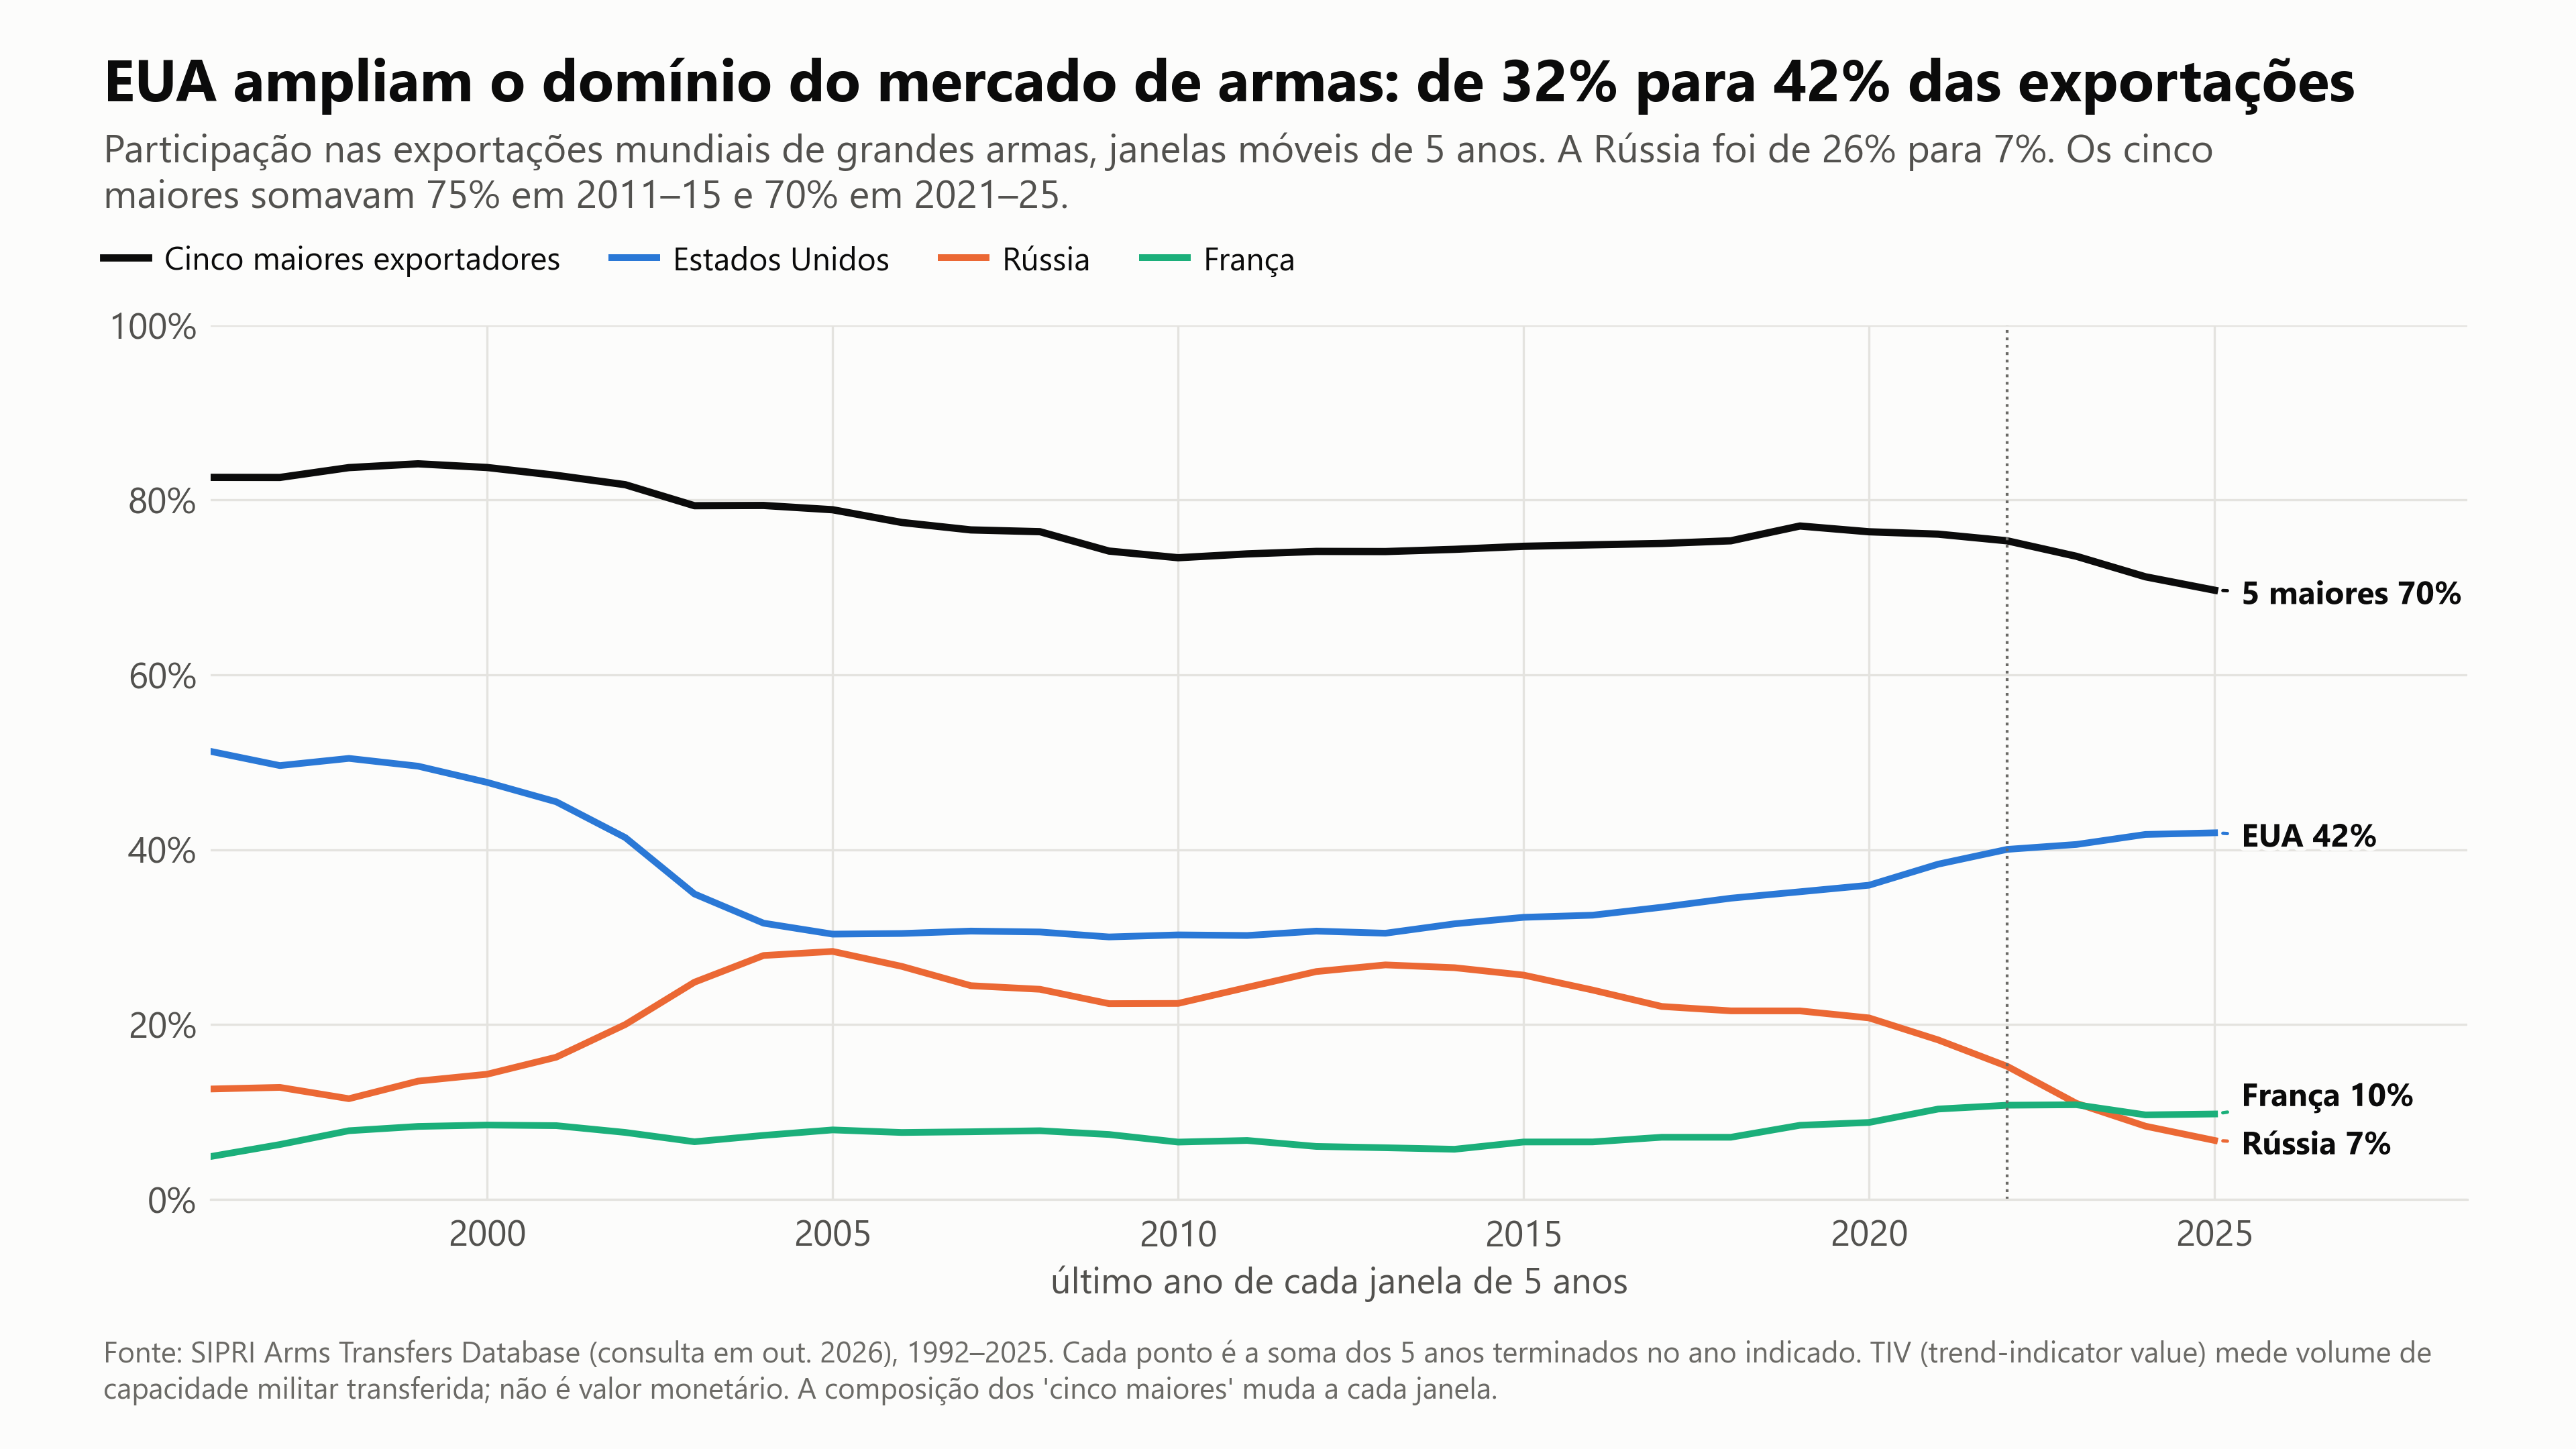

In [9]:
if (c.PROCESSED / "armas_tiv.csv").exists():
    mostrar(7)

## 8. Conflito e comércio de armas

Os maiores importadores e exportadores de 2021–2025, marcados conforme o governo tenha sido parte primária de algum conflito ativo no período. É uma associação: não diz se as armas causaram a guerra, se a guerra causou a compra, ou nenhuma das duas coisas.

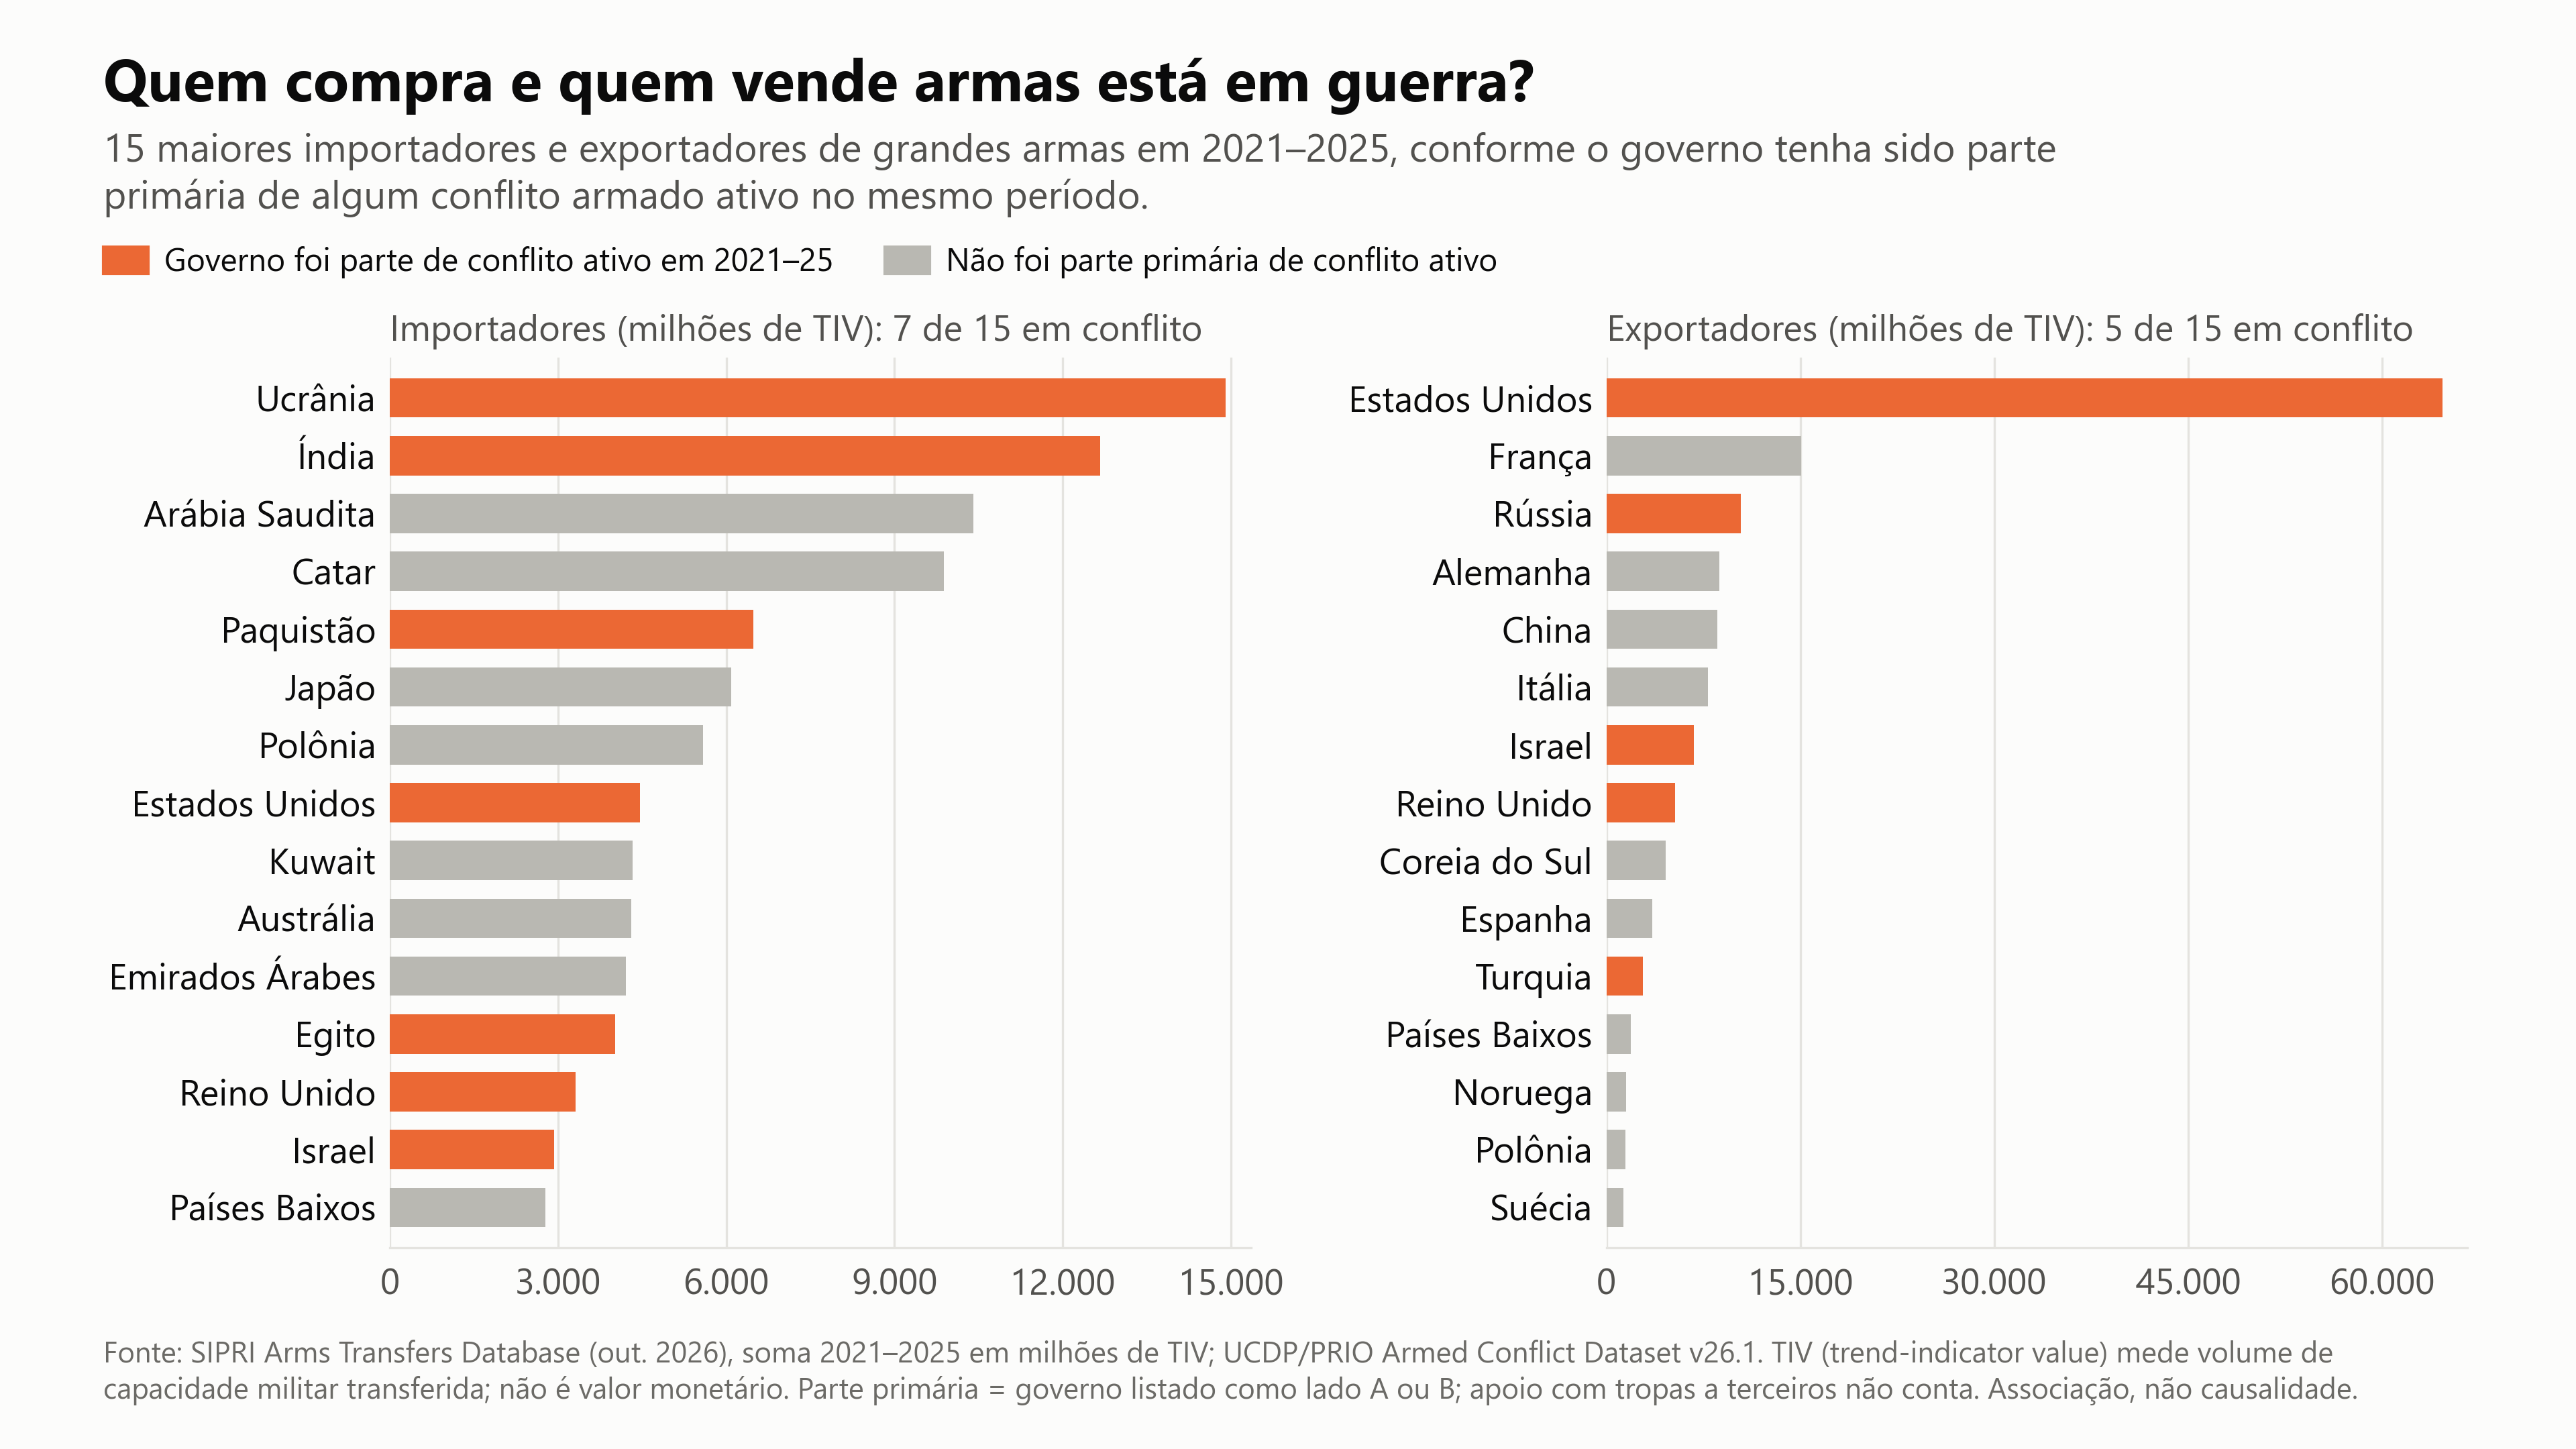

In [10]:
if (c.PROCESSED / "armas_tiv.csv").exists():
    mostrar(8)

## 9. Gasto militar e mortes em batalha

Cada ponto é um país cujo governo foi parte de conflito com mortes registradas em 2021–2025. As duas escalas são logarítmicas. Países sem dado de gasto ficam fora e são listados no rodapé.

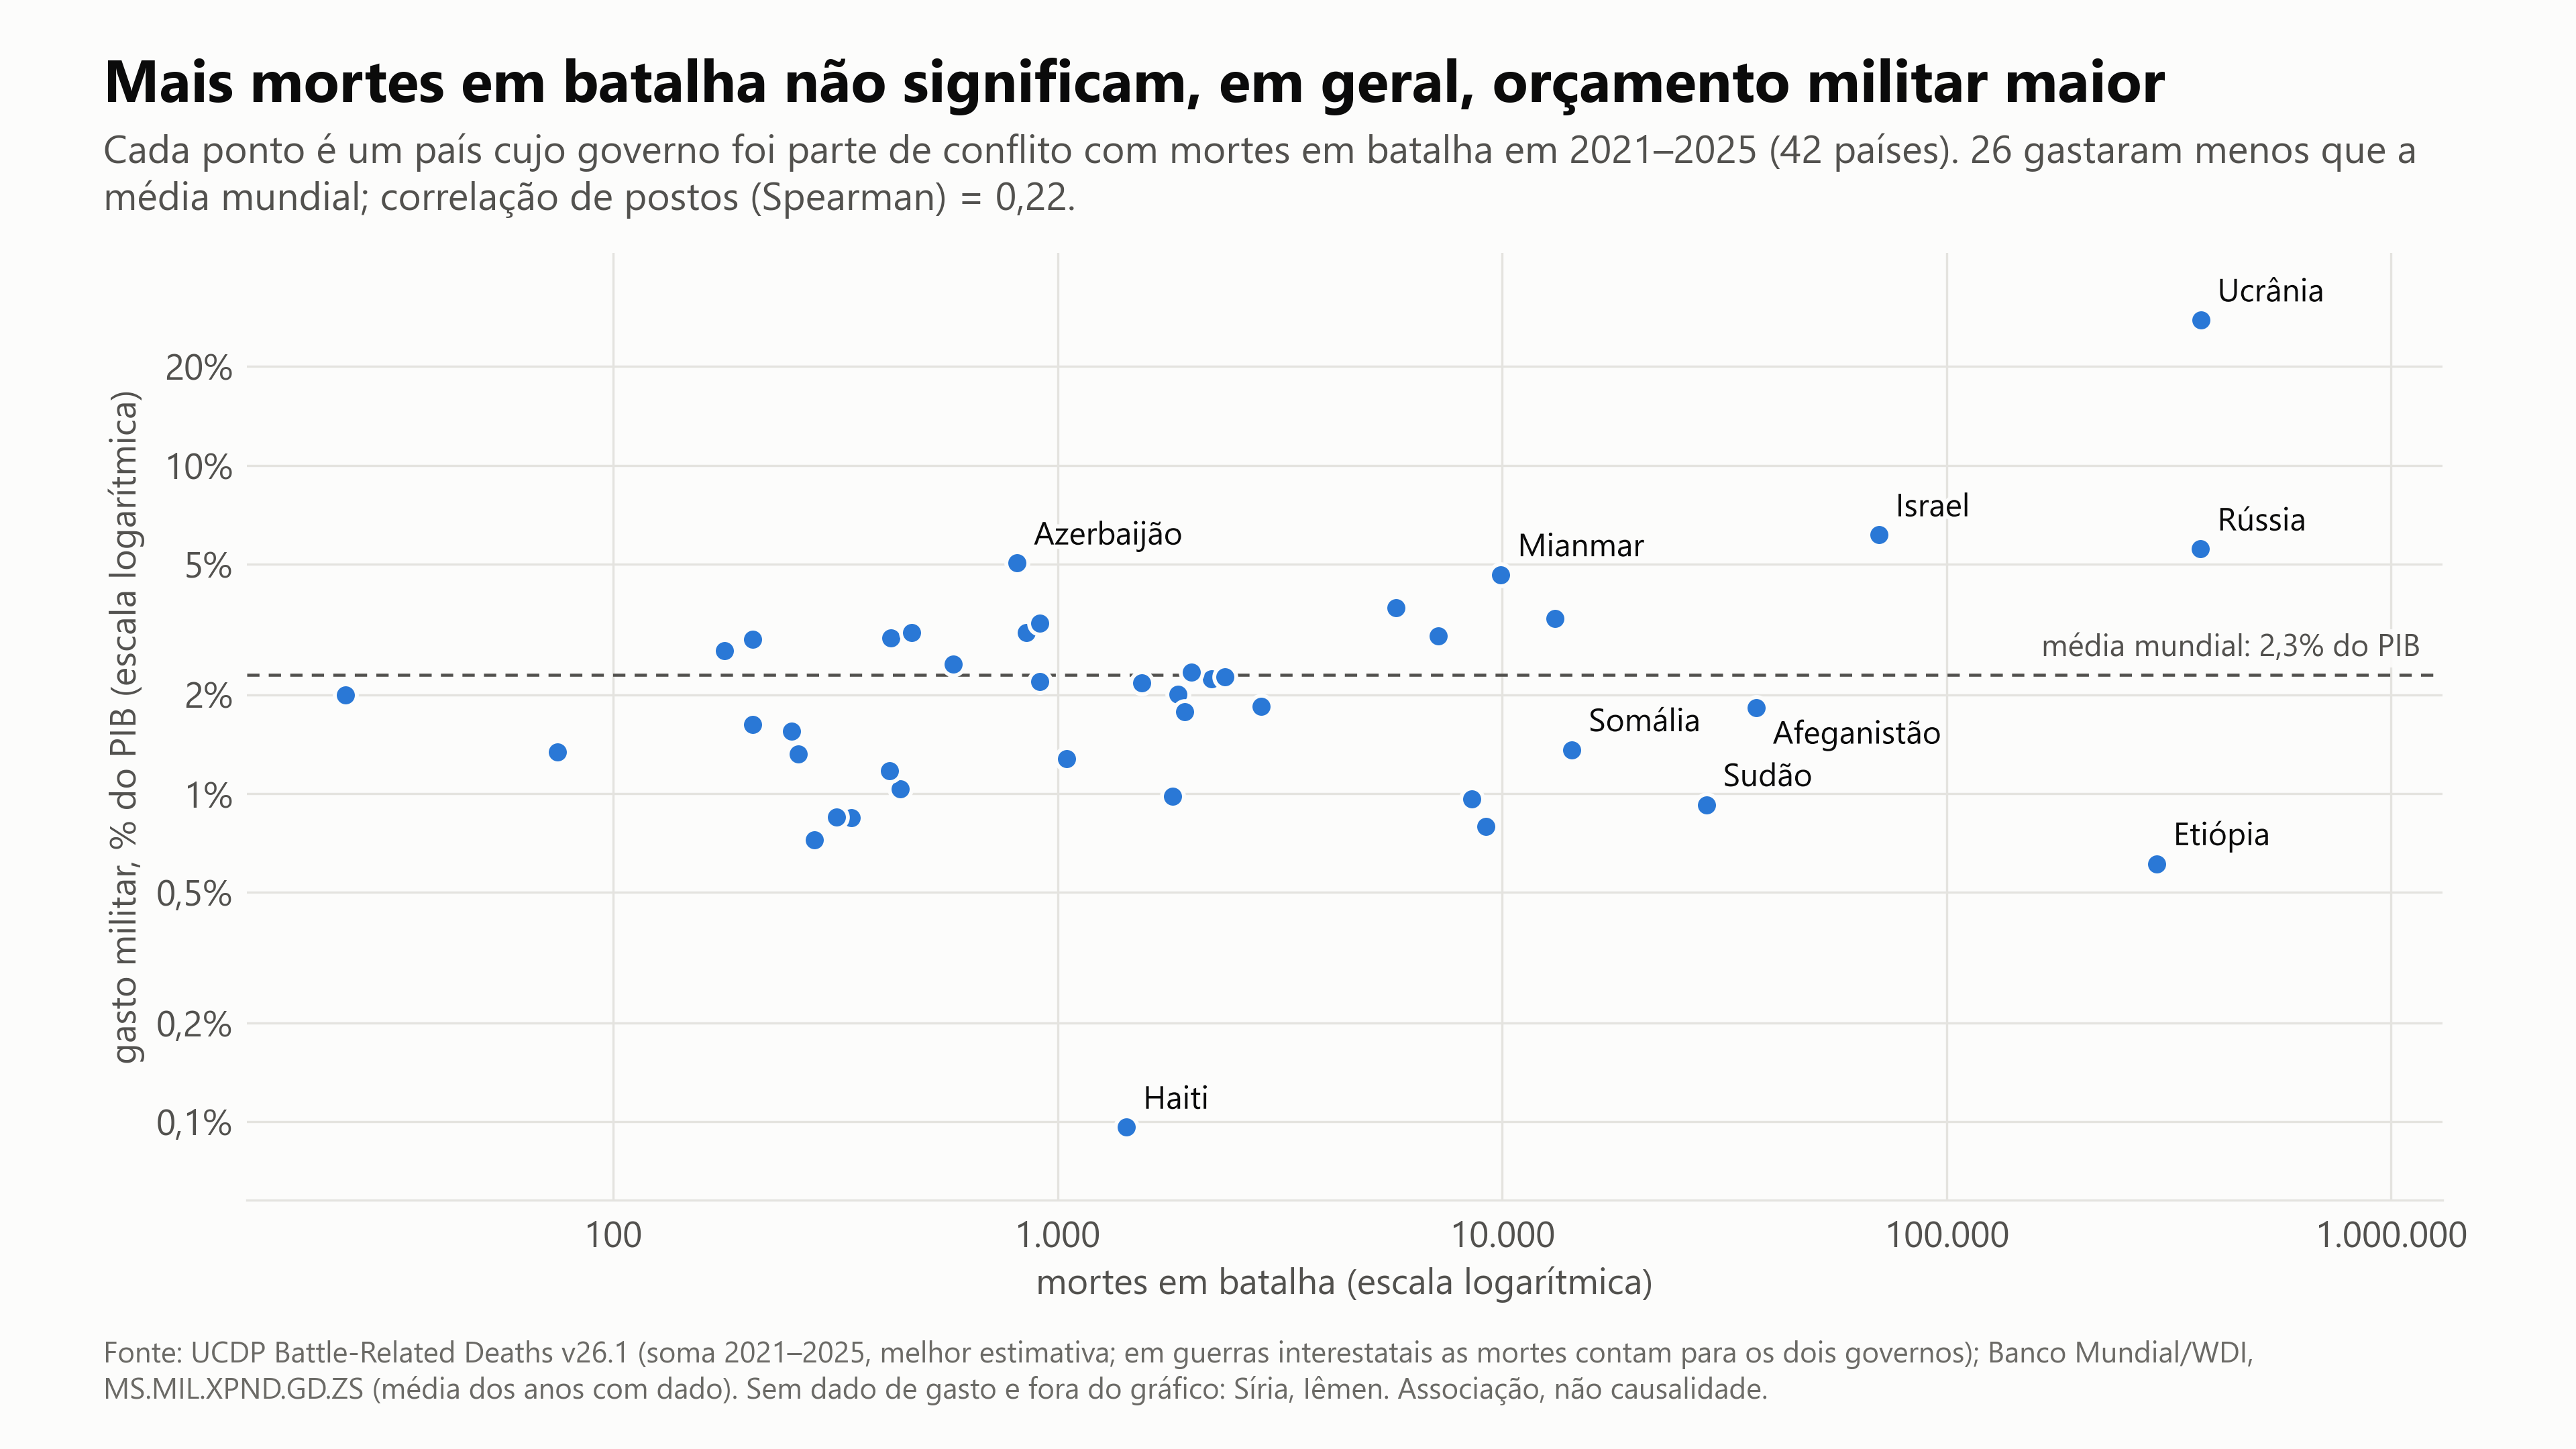

Sem dado de gasto militar no período: ['Síria', 'Iêmen']


,pais,mortes,% PIB (média),anos com dado de gasto
40,Ucrânia,"372.853,0","27,7",5
29,Rússia,"372.766,0","5,6",5
11,Etiópia,"296.675,0","0,6",5
18,Israel,"70.361,0","6,1",5
0,Afeganistão,"37.235,0","1,8",1
31,Sudão,"28.791,0","0,9",1
32,Somália,"14.351,0","1,4",5
5,Burkina Faso,"13.132,0","3,4",5
23,Mianmar,"9.939,0","4,6",4
26,Nigéria,"9.178,0","0,8",5


In [11]:
mostrar(9)
d, sem = g.dados_fig09()
print("Sem dado de gasto militar no período:", [c.nome_pt(i) for i in sem])
d.assign(pais=d.iso3.map(c.nome_pt)).nlargest(10, "mortes")[["pais", "mortes", "pct_pib", "count"]].rename(
    columns={"pct_pib": "% PIB (média)", "count": "anos com dado de gasto"})

## 10. Brasil

O Brasil não aparece nas bases de conflito armado, mas convive com níveis de violência letal comparáveis aos de países em guerra. A figura soma, a partir do Sinesp/MJSP, homicídio doloso, feminicídio, latrocínio, lesão corporal seguida de morte e morte por intervenção de agente do Estado, e destaca esta última.

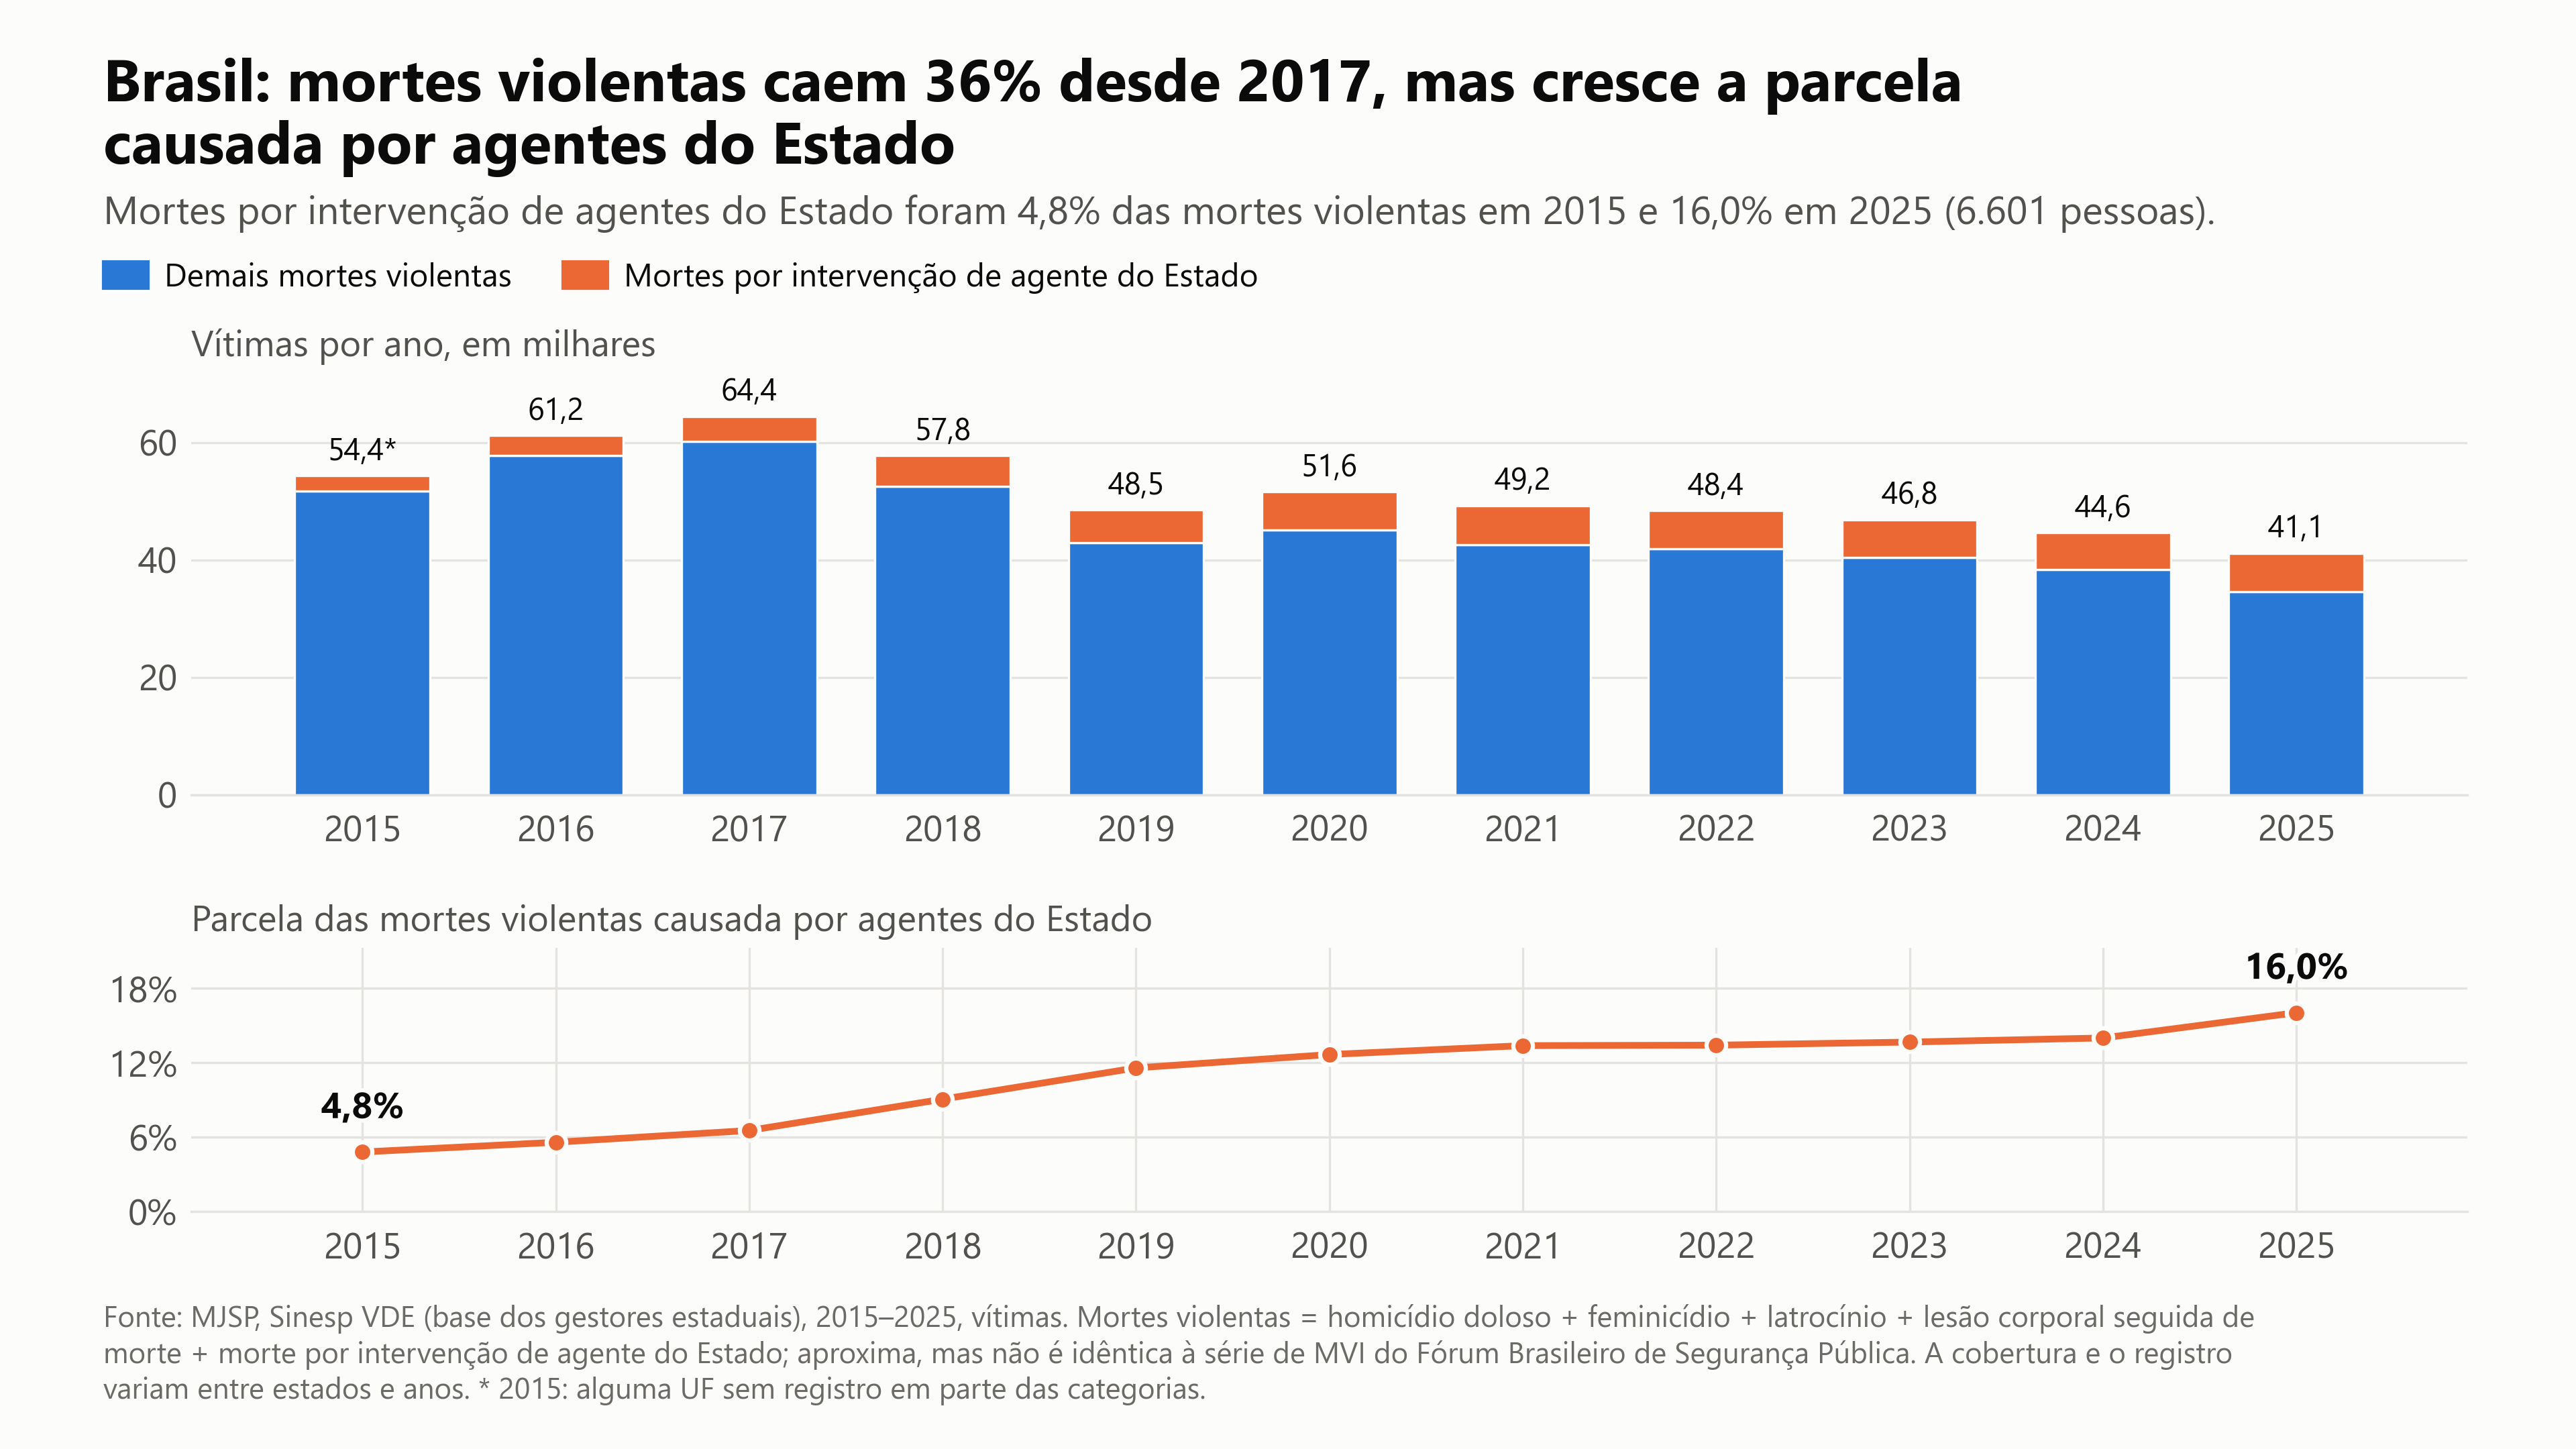

,policia,demais,total,pct_policia
ano,,,,
2015,"2.616,0","51.734,0","54.350,0","4,8"
2016,"3.426,0","57.763,0","61.189,0","5,6"
2017,"4.220,0","60.215,0","64.435,0","6,5"
2018,"5.239,0","52.514,0","57.753,0","9,1"
2019,"5.627,0","42.914,0","48.541,0","11,6"
2020,"6.542,0","45.087,0","51.629,0","12,7"
2021,"6.593,0","42.651,0","49.244,0","13,4"
2022,"6.497,0","41.895,0","48.392,0","13,4"
2023,"6.406,0","40.436,0","46.842,0","13,7"


In [12]:
b = g.dados_fig10()
if b is not None:
    mostrar(10)
    display(b)
else:
    print("Sem dados do Sinesp em data/raw/sinesp: ver data/README.md.")

## Conferência

`src/verifica.py` imprime todos os números citados no README. Rode `python -m src.verifica` depois de qualquer atualização dos dados e compare com o README antes de publicar.